In [1]:
import pandas as pd


beneficiary = pd.read_csv("datasets/provider/Train_Beneficiarydata.csv")
inpatient = pd.read_csv("datasets/provider/Train_Inpatientdata.csv")
outpatient = pd.read_csv("datasets/provider/Train_Outpatientdata.csv")
train = pd.read_csv("datasets/provider/Train.csv")


In [2]:

import numpy as np
import pandas as pd


beneficiary = pd.read_csv("datasets/provider/Train_Beneficiarydata.csv")
inpatient = pd.read_csv("datasets/provider/Train_Inpatientdata.csv")
outpatient = pd.read_csv("datasets/provider/Train_Outpatientdata.csv")
train = pd.read_csv("datasets/provider/Train.csv")


print("All datasets loaded successfully!")




All datasets loaded successfully!


In [3]:
print("Beneficiary Data:")
print(beneficiary.head())

Beneficiary Data:
      BeneID         DOB  DOD  Gender  Race RenalDiseaseIndicator  State  \
0  BENE11001  1943-01-01  NaN       1     1                     0     39   
1  BENE11002  1936-09-01  NaN       2     1                     0     39   
2  BENE11003  1936-08-01  NaN       1     1                     0     52   
3  BENE11004  1922-07-01  NaN       1     1                     0     39   
4  BENE11005  1935-09-01  NaN       1     1                     0     24   

   County  NoOfMonths_PartACov  NoOfMonths_PartBCov  ...  \
0     230                   12                   12  ...   
1     280                   12                   12  ...   
2     590                   12                   12  ...   
3     270                   12                   12  ...   
4     680                   12                   12  ...   

   ChronicCond_Depression  ChronicCond_Diabetes  ChronicCond_IschemicHeart  \
0                       1                     1                          1   
1       

In [4]:


print("\n===== DATASET SHAPES =====")

print("Beneficiary:", beneficiary.shape)
print("Inpatient:", inpatient.shape)
print("Outpatient:", outpatient.shape)
print("Train:", train.shape)


# ============================================================
# 3. CHECK COLUMNS
# ============================================================

print("\n===== COLUMNS =====")

print("Beneficiary:")
print(beneficiary.columns.tolist())

print("\nInpatient:")
print(inpatient.columns.tolist())

print("\nOutpatient:")
print(outpatient.columns.tolist())

print("\nTrain:")
print(train.columns.tolist())



===== DATASET SHAPES =====
Beneficiary: (138556, 25)
Inpatient: (40474, 30)
Outpatient: (517737, 27)
Train: (5410, 2)

===== COLUMNS =====
Beneficiary:
['BeneID', 'DOB', 'DOD', 'Gender', 'Race', 'RenalDiseaseIndicator', 'State', 'County', 'NoOfMonths_PartACov', 'NoOfMonths_PartBCov', 'ChronicCond_Alzheimer', 'ChronicCond_Heartfailure', 'ChronicCond_KidneyDisease', 'ChronicCond_Cancer', 'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression', 'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart', 'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis', 'ChronicCond_stroke', 'IPAnnualReimbursementAmt', 'IPAnnualDeductibleAmt', 'OPAnnualReimbursementAmt', 'OPAnnualDeductibleAmt']

Inpatient:
['BeneID', 'ClaimID', 'ClaimStartDt', 'ClaimEndDt', 'Provider', 'InscClaimAmtReimbursed', 'AttendingPhysician', 'OperatingPhysician', 'OtherPhysician', 'AdmissionDt', 'ClmAdmitDiagnosisCode', 'DeductibleAmtPaid', 'DischargeDt', 'DiagnosisGroupCode', 'ClmDiagnosisCode_1', 'ClmDiagnosisCode_2', 'Clm

In [5]:


# ============================================================
# 4. CLEAN DATE COLUMNS
# ============================================================

beneficiary["DOB"] = pd.to_datetime(
    beneficiary["DOB"],
    errors="coerce"
)

beneficiary["DOD"] = pd.to_datetime(
    beneficiary["DOD"],
    errors="coerce"
)

inpatient["ClaimStartDt"] = pd.to_datetime(
    inpatient["ClaimStartDt"],
    errors="coerce"
)

inpatient["ClaimEndDt"] = pd.to_datetime(
    inpatient["ClaimEndDt"],
    errors="coerce"
)

outpatient["ClaimStartDt"] = pd.to_datetime(
    outpatient["ClaimStartDt"],
    errors="coerce"
)

outpatient["ClaimEndDt"] = pd.to_datetime(
    outpatient["ClaimEndDt"],
    errors="coerce"
)

print("\nDates cleaned successfully!")



Dates cleaned successfully!


In [6]:



# ============================================================
# 5. MISSING VALUES
# ============================================================

print("\n===== MISSING VALUES =====")

print("\nBeneficiary:")
print(beneficiary.isnull().sum())

print("\nInpatient:")
print(inpatient.isnull().sum())

print("\nOutpatient:")
print(outpatient.isnull().sum())

print("\nTrain:")
print(train.isnull().sum())



===== MISSING VALUES =====

Beneficiary:
BeneID                                  0
DOB                                     0
DOD                                137135
Gender                                  0
Race                                    0
RenalDiseaseIndicator                   0
State                                   0
County                                  0
NoOfMonths_PartACov                     0
NoOfMonths_PartBCov                     0
ChronicCond_Alzheimer                   0
ChronicCond_Heartfailure                0
ChronicCond_KidneyDisease               0
ChronicCond_Cancer                      0
ChronicCond_ObstrPulmonary              0
ChronicCond_Depression                  0
ChronicCond_Diabetes                    0
ChronicCond_IschemicHeart               0
ChronicCond_Osteoporasis                0
ChronicCond_rheumatoidarthritis         0
ChronicCond_stroke                      0
IPAnnualReimbursementAmt                0
IPAnnualDeductibleAmt             

In [7]:



# handling missing numerical values using median

for df in [beneficiary, inpatient, outpatient]:

    numeric_columns = df.select_dtypes(
        include=["number"]
    ).columns

    df[numeric_columns] = df[numeric_columns].fillna(
        df[numeric_columns].median()
    )



In [8]:
## Handling missing categorical values using "Unknown"
for df in [beneficiary, inpatient, outpatient, train]:

    categorical_columns = df.select_dtypes(
        include=["object"]
    ).columns

    df[categorical_columns] = df[categorical_columns].fillna(
        "Unknown"
    )



In [9]:
## drop duplicates row  from all datasets

beneficiary = beneficiary.drop_duplicates()
inpatient = inpatient.drop_duplicates()
outpatient = outpatient.drop_duplicates()
train = train.drop_duplicates()

print("\nDuplicates removed.")



Duplicates removed.


In [10]:
## convert PotentialFraud column to binary values

train["PotentialFraud"] = train["PotentialFraud"].map({
    "No": 0,
    "Yes": 1
})



In [11]:
## Checking the distribution of the fraud label


print("\n===== FRAUD LABEL DISTRIBUTION =====")

print(train["PotentialFraud"].value_counts())

print("\nFraud percentage:")

print(
    train["PotentialFraud"]
    .value_counts(normalize=True)
    .mul(100)
)



===== FRAUD LABEL DISTRIBUTION =====
PotentialFraud
0    4904
1     506
Name: count, dtype: int64

Fraud percentage:
PotentialFraud
0    90.64695
1     9.35305
Name: proportion, dtype: float64


### From above  method we know class imbalance ratio is around 10:1 

In [12]:
print(90.64695/9.35305)


9.691699499093879


In [13]:
## Important id null checks

print("\n===== IMPORTANT ID CHECK =====")

print(
    "Missing Beneficiary IDs:",
    beneficiary["BeneID"].isnull().sum()
)

print(
    "Missing Inpatient Claim IDs:",
    inpatient["ClaimID"].isnull().sum()
)

print(
    "Missing Inpatient Provider IDs:",
    inpatient["Provider"].isnull().sum()
)

print(
    "Missing Outpatient Claim IDs:",
    outpatient["ClaimID"].isnull().sum()
)

print(
    "Missing Outpatient Provider IDs:",
    outpatient["Provider"].isnull().sum()
)

print(
    "Missing Train Provider IDs:",
    train["Provider"].isnull().sum()
)




===== IMPORTANT ID CHECK =====
Missing Beneficiary IDs: 0
Missing Inpatient Claim IDs: 0
Missing Inpatient Provider IDs: 0
Missing Outpatient Claim IDs: 0
Missing Outpatient Provider IDs: 0
Missing Train Provider IDs: 0


In [14]:

# ============================================================
# 12. FINAL DATA PREVIEW
# ============================================================

print("\n===== FINAL DATA PREVIEW =====")

print("\nBeneficiary:")
print(beneficiary.head())

print("\nInpatient:")
print(inpatient.head())

print("\nOutpatient:")
print(outpatient.head())

print("\nTrain:")
print(train.head())


# ============================================================
# 13. FINAL CHECK
# ============================================================

print("\n===== FINAL DATASET SIZES =====")

print("Beneficiary:", beneficiary.shape)
print("Inpatient:", inpatient.shape)
print("Outpatient:", outpatient.shape)
print("Train:", train.shape)

print("\nSTEP 01 COMPLETED SUCCESSFULLY!")


===== FINAL DATA PREVIEW =====

Beneficiary:
      BeneID        DOB DOD  Gender  Race RenalDiseaseIndicator  State  \
0  BENE11001 1943-01-01 NaT       1     1                     0     39   
1  BENE11002 1936-09-01 NaT       2     1                     0     39   
2  BENE11003 1936-08-01 NaT       1     1                     0     52   
3  BENE11004 1922-07-01 NaT       1     1                     0     39   
4  BENE11005 1935-09-01 NaT       1     1                     0     24   

   County  NoOfMonths_PartACov  NoOfMonths_PartBCov  ...  \
0     230                   12                   12  ...   
1     280                   12                   12  ...   
2     590                   12                   12  ...   
3     270                   12                   12  ...   
4     680                   12                   12  ...   

   ChronicCond_Depression  ChronicCond_Diabetes  ChronicCond_IschemicHeart  \
0                       1                     1                       

### Feature Engineering

In [15]:
import pandas as pd
import numpy as np

# ============================================================
# 02 FEATURE ENGINEERING
# ============================================================


# ============================================================
# 1. COMBINE INPATIENT + OUTPATIENT
# ============================================================

# Add claim type before combining
inpatient["ClaimType"] = "Inpatient"
outpatient["ClaimType"] = "Outpatient"

# Both datasets have different columns.
# concat() automatically creates missing columns as NaN.
claims = pd.concat(
    [inpatient, outpatient],
    ignore_index=True,
    sort=False
)

print("Combined claims shape:", claims.shape)

print("\nClaim types:")
print(claims["ClaimType"].value_counts())



Combined claims shape: (558211, 31)

Claim types:
ClaimType
Outpatient    517737
Inpatient      40474
Name: count, dtype: int64


In [16]:

## Calculate claim duration in days

claims["ClaimStartDt"] = pd.to_datetime(
    claims["ClaimStartDt"],
    errors="coerce"
)

claims["ClaimEndDt"] = pd.to_datetime(
    claims["ClaimEndDt"],
    errors="coerce"
)

claims["ClaimDuration"] = (
    claims["ClaimEndDt"] - claims["ClaimStartDt"]
).dt.days

# Replace negative durations with NaN
claims.loc[
    claims["ClaimDuration"] < 0,
    "ClaimDuration"
] = np.nan



In [17]:
# Provider-level features 
# contains features like total claims, unique beneficiaries, financial features,all claim types, unique diagnoses, and unique procedures.

provider_features = claims.groupby("Provider").agg(

    # Number of claims
    TotalClaims=("ClaimID", "count"),

    # Number of beneficiaries
    UniqueBeneficiaries=("BeneID", "nunique"),

    # Number of physicians
    UniqueAttendingPhysicians=("AttendingPhysician", "nunique"),
    UniqueOperatingPhysicians=("OperatingPhysician", "nunique"),
    UniqueOtherPhysicians=("OtherPhysician", "nunique"),

    # Financial features
    TotalReimbursement=(
        "InscClaimAmtReimbursed",
        "sum"
    ),

    AverageReimbursement=(
        "InscClaimAmtReimbursed",
        "mean"
    ),

    MaximumReimbursement=(
        "InscClaimAmtReimbursed",
        "max"
    ),

    TotalDeductible=(
        "DeductibleAmtPaid",
        "sum"
    ),

    AverageDeductible=(
        "DeductibleAmtPaid",
        "mean"
    ),

    # Claim duration
    AverageClaimDuration=(
        "ClaimDuration",
        "mean"
    ),

    MaximumClaimDuration=(
        "ClaimDuration",
        "max"
    )

).reset_index()


# ============================================================
# 4. INPATIENT / OUTPATIENT COUNTS
# ============================================================

claim_type_counts = pd.crosstab(
    claims["Provider"],
    claims["ClaimType"]
).reset_index()

claim_type_counts = claim_type_counts.rename(
    columns={
        "Inpatient": "InpatientClaims",
        "Outpatient": "OutpatientClaims"
    }
)


In [18]:


# Merge with provider features
provider_features = provider_features.merge(
    claim_type_counts,
    on="Provider",
    how="left"
)


# ============================================================
# 5. DIAGNOSIS FEATURES FOR PROVIDERS
# ============================================================

diagnosis_columns = [
    f"ClmDiagnosisCode_{i}"
    for i in range(1, 11)
]

# Keep only columns that actually exist
diagnosis_columns = [
    col for col in diagnosis_columns
    if col in claims.columns
]

# Convert diagnosis columns into one long column
diagnosis_long = claims[
    ["Provider"] + diagnosis_columns
].melt(
    id_vars="Provider",
    value_name="DiagnosisCode"
)

# Remove missing diagnosis codes
diagnosis_long = diagnosis_long.dropna(
    subset=["DiagnosisCode"]
)

# Number of unique diagnoses per provider
provider_diagnosis = diagnosis_long.groupby(
    "Provider"
)["DiagnosisCode"].nunique().reset_index()

provider_diagnosis = provider_diagnosis.rename(
    columns={
        "DiagnosisCode": "UniqueDiagnoses"
    }
)

provider_features = provider_features.merge(
    provider_diagnosis,
    on="Provider",
    how="left"
)


# ============================================================
# 6. PROCEDURE FEATURES FOR PROVIDERS
# ============================================================

procedure_columns = [
    f"ClmProcedureCode_{i}"
    for i in range(1, 7)
]

procedure_columns = [
    col for col in procedure_columns
    if col in claims.columns
]

procedure_long = claims[
    ["Provider"] + procedure_columns
].melt(
    id_vars="Provider",
    value_name="ProcedureCode"
)

procedure_long = procedure_long.dropna(
    subset=["ProcedureCode"]
)

provider_procedure = procedure_long.groupby(
    "Provider"
)["ProcedureCode"].nunique().reset_index()

provider_procedure = provider_procedure.rename(
    columns={
        "ProcedureCode": "UniqueProcedures"
    }
)

provider_features = provider_features.merge(
    provider_procedure,
    on="Provider",
    how="left"
)


# ============================================================
# 7. PROVIDER FEATURE: REIMBURSEMENT PER CLAIM
# ============================================================

provider_features["ReimbursementPerClaim"] = (
    provider_features["TotalReimbursement"]
    / provider_features["TotalClaims"]
)


# ============================================================
# 8. PROVIDER FEATURE: DEDUCTIBLE PER CLAIM
# ============================================================

provider_features["DeductiblePerClaim"] = (
    provider_features["TotalDeductible"]
    / provider_features["TotalClaims"]
)


# ============================================================
# 9. PROVIDER FEATURE: CLAIM TYPE RATIO
# ============================================================

provider_features["InpatientRatio"] = (
    provider_features["InpatientClaims"]
    / provider_features["TotalClaims"]
)

provider_features["OutpatientRatio"] = (
    provider_features["OutpatientClaims"]
    / provider_features["TotalClaims"]
)


# ============================================================
# 10. FILL ONLY NUMERIC FEATURE MISSING VALUES
# ============================================================

numeric_columns = provider_features.select_dtypes(
    include=["number"]
).columns

provider_features[numeric_columns] = (
    provider_features[numeric_columns]
    .fillna(0)
)


# ============================================================
# 11. CREATE BENEFICIARY FEATURES
# ============================================================

# Calculate age at the beginning of the claim period
beneficiary_features = beneficiary[
    [
        "BeneID",
        "DOB",
        "Gender",
        "Race",
        "RenalDiseaseIndicator",
        "State",
        "County",
        "NoOfMonths_PartACov",
        "NoOfMonths_PartBCov",
        "ChronicCond_Alzheimer",
        "ChronicCond_Heartfailure",
        "ChronicCond_KidneyDisease",
        "ChronicCond_Cancer",
        "ChronicCond_ObstrPulmonary",
        "ChronicCond_Depression",
        "ChronicCond_Diabetes",
        "ChronicCond_IschemicHeart",
        "ChronicCond_Osteoporasis",
        "ChronicCond_rheumatoidarthritis",
        "ChronicCond_stroke",
        "IPAnnualReimbursementAmt",
        "IPAnnualDeductibleAmt",
        "OPAnnualReimbursementAmt",
        "OPAnnualDeductibleAmt"
    ]
].copy()


# Calculate approximate age
reference_date = pd.Timestamp("2009-01-01")

beneficiary_features["Age"] = (
    reference_date - beneficiary_features["DOB"]
).dt.days / 365.25


# Remove DOB after age calculation
beneficiary_features = beneficiary_features.drop(
    columns=["DOB"]
)


# ============================================================
# 12. BENEFICIARY CLAIM STATISTICS
# ============================================================

beneficiary_claim_stats = claims.groupby(
    "BeneID"
).agg(

    BeneficiaryTotalClaims=("ClaimID", "count"),

    BeneficiaryTotalReimbursement=(
        "InscClaimAmtReimbursed",
        "sum"
    ),

    BeneficiaryAverageReimbursement=(
        "InscClaimAmtReimbursed",
        "mean"
    ),

    BeneficiaryUniqueProviders=(
        "Provider",
        "nunique"
    ),

    BeneficiaryUniquePhysicians=(
        "AttendingPhysician",
        "nunique"
    )

).reset_index()


beneficiary_features = beneficiary_features.merge(
    beneficiary_claim_stats,
    on="BeneID",
    how="left"
)


# ============================================================
# 13. CLAIM FEATURES
# ============================================================

claim_features = claims[
    [
        "ClaimID",
        "BeneID",
        "Provider",
        "ClaimType",
        "ClaimStartDt",
        "ClaimEndDt",
        "InscClaimAmtReimbursed",
        "DeductibleAmtPaid",
        "ClaimDuration"
    ]
].copy()


# ============================================================
# 14. PHYSICIAN FEATURES
# ============================================================

# Create physician-provider relationships
physician_columns = [
    "AttendingPhysician",
    "OperatingPhysician",
    "OtherPhysician"
]

physician_long = claims[
    ["Provider"] + physician_columns
].melt(
    id_vars=["Provider"],
    value_name="Physician"
)

# Remove missing physicians
physician_long = physician_long.dropna(
    subset=["Physician"]
)


# Physician statistics
physician_features = physician_long.groupby(
    "Physician"
).agg(

    PhysicianTotalClaims=(
        "Provider",
        "count"
    ),

    PhysicianUniqueProviders=(
        "Provider",
        "nunique"
    )

).reset_index()


# ============================================================
# 15. DIAGNOSIS FEATURES
# ============================================================

diagnosis_features = diagnosis_long.groupby(
    "DiagnosisCode"
).agg(

    DiagnosisTotalClaims=(
        "Provider",
        "count"
    ),

    DiagnosisUniqueProviders=(
        "Provider",
        "nunique"
    )

).reset_index()


# ============================================================
# 16. PROCEDURE FEATURES
# ============================================================

procedure_features = procedure_long.groupby(
    "ProcedureCode"
).agg(

    ProcedureTotalClaims=(
        "Provider",
        "count"
    ),

    ProcedureUniqueProviders=(
        "Provider",
        "nunique"
    )

).reset_index()


# ============================================================
# 17. ADD FRAUD LABELS TO PROVIDER FEATURES
# ============================================================

provider_features = provider_features.merge(
    train[
        ["Provider", "PotentialFraud"]
    ],
    on="Provider",
    how="left"
)


# ============================================================
# 18. CHECK PROVIDER FEATURES
# ============================================================

print("\n======================================")
print("PROVIDER FEATURES")
print("======================================")

print(provider_features.head())

print("\nProvider feature shape:")
print(provider_features.shape)
provider_features.to_csv("./datasets/features_const/providers_features.csv")

# ============================================================
# 19. CHECK BENEFICIARY FEATURES
# ============================================================

print("\n======================================")
print("BENEFICIARY FEATURES")
print("======================================")

print(beneficiary_features.head())

print("\nBeneficiary feature shape:")
print(beneficiary_features.shape)
beneficiary_features.to_csv("./datasets/features_const/beneficiary_features.csv")



# ============================================================
# 20. CHECK CLAIM FEATURES
# ============================================================

print("\n======================================")
print("CLAIM FEATURES")
print("======================================")

print(claim_features.head())

print("\nClaim feature shape:")
print(claim_features.shape)

claim_features.to_csv("./datasets/features_const/claim_features.csv")




# ============================================================
# 21. CHECK PHYSICIAN FEATURES
# ============================================================

print("\n======================================")
print("PHYSICIAN FEATURES")
print("======================================")

print(physician_features.head())

print("\nPhysician feature shape:")
print(physician_features.shape)
physician_features.to_csv("./datasets/features_const/physician_features.csv")


# ============================================================
# 22. CHECK DIAGNOSIS FEATURES
# ============================================================

print("\n======================================")
print("DIAGNOSIS FEATURES")
print("======================================")

print(diagnosis_features.head())

print("\nDiagnosis feature shape:")
print(diagnosis_features.shape)
diagnosis_features.to_csv("./datasets/features_const/diagnosis_features.csv")

# ============================================================
# 23. CHECK PROCEDURE FEATURES
# ============================================================

print("\n======================================")
print("PROCEDURE FEATURES")
print("======================================")

print(procedure_features.head())

print("\nProcedure feature shape:")
print(procedure_features.shape)
procedure_features.to_csv("./datasets/features_const/procedure_features.csv")


# ============================================================
# 24. FINAL CHECK
# ============================================================

print("\n======================================")
print("STEP 02 FEATURE ENGINEERING COMPLETED")
print("======================================")


PROVIDER FEATURES
   Provider  TotalClaims  UniqueBeneficiaries  UniqueAttendingPhysicians  \
0  PRV51001           25                   24                         14   
1  PRV51003          132                  117                         44   
2  PRV51004          149                  138                         38   
3  PRV51005         1165                  495                          7   
4  PRV51007           72                   58                         10   

   UniqueOperatingPhysicians  UniqueOtherPhysicians  TotalReimbursement  \
0                          6                      9              104640   
1                          8                     23              605670   
2                         20                     27               52170   
3                          7                      5              280910   
4                          6                      8               33710   

   AverageReimbursement  MaximumReimbursement  TotalDeductible  ...  \
0 

In [19]:
print(len(beneficiary_features))

138556


In [20]:

# filepath: /home/thirilo/Documents/Mythings/Projects/coding/Preprocess.ipynb
# Federated heterogeneous-GNN simulation.
# Run after STEP 03 has saved datasets/graph/hetero_data.pt.
# This is a research simulation, not a privacy guarantee.

import copy
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv


# ---------------------------------------------------------------------
# Reproducibility, graph loading, and real-only train/validation/test split
# ---------------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
graph_path = "./datasets/graph/hetero_data.pt"

fed_graph = torch.load(graph_path, map_location="cpu", weights_only=False)
labels = fed_graph["provider"].y.long().cpu().numpy()

if not np.isin(labels, [0, 1]).all():
    raise ValueError("Provider labels must be encoded as 0/1.")

real_indices = np.arange(len(labels))
train_idx, test_idx = train_test_split(
    real_indices, test_size=0.20, random_state=SEED, stratify=labels
)
train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=SEED,
    stratify=labels[train_idx],
)

y_train_real = labels[train_idx]
y_val = labels[val_idx]
y_test = labels[test_idx]

print(
    f"Real providers: train={len(train_idx)}, "
    f"validation={len(val_idx)}, test={len(test_idx)}"
)


# ---------------------------------------------------------------------
# Training-only preprocessing and label-conditioned tabular DDPM
# ---------------------------------------------------------------------

# Provider feature preprocessing is fitted only on real training providers.
provider_x = fed_graph["provider"].x.cpu().numpy().astype(np.float32)
scaler = StandardScaler()
X_train_real = scaler.fit_transform(provider_x[train_idx]).astype(np.float32)

# Transform all graph provider features using the training-fitted scaler.
fed_graph["provider"].x = torch.tensor(
    scaler.transform(provider_x).astype(np.float32)
)

ddpm_device = device
diffusion_steps = 100
feature_count = X_train_real.shape[1]


class TabularNoisePredictor(nn.Module):
    def __init__(self, input_dim, steps, hidden=128, time_dim=32, label_dim=16):
        super().__init__()
        self.time_embedding = nn.Embedding(steps, time_dim)
        self.label_embedding = nn.Embedding(2, label_dim)
        self.network = nn.Sequential(
            nn.Linear(input_dim + time_dim + label_dim, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, input_dim),
        )

    def forward(self, x, timestep, label):
        condition = torch.cat(
            [x, self.time_embedding(timestep), self.label_embedding(label)],
            dim=1,
        )
        return self.network(condition)


betas = torch.linspace(1e-4, 0.02, diffusion_steps, device=ddpm_device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

ddpm = TabularNoisePredictor(feature_count, diffusion_steps).to(ddpm_device)
ddpm_optimizer = torch.optim.AdamW(ddpm.parameters(), lr=1e-3)
ddpm_x = torch.tensor(X_train_real, dtype=torch.float32)
ddpm_y = torch.tensor(y_train_real, dtype=torch.long)
ddpm_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(ddpm_x, ddpm_y),
    batch_size=128,
    shuffle=True,
)

DDPM_EPOCHS = 100
for epoch in range(DDPM_EPOCHS):
    ddpm.train()
    total_loss = 0.0

    for clean_x, labels_batch in ddpm_loader:
        clean_x = clean_x.to(ddpm_device)
        labels_batch = labels_batch.to(ddpm_device)
        timestep = torch.randint(
            0, diffusion_steps, (len(clean_x),), device=ddpm_device
        )
        noise = torch.randn_like(clean_x)
        a_bar = alpha_bars[timestep].unsqueeze(1)
        noisy_x = a_bar.sqrt() * clean_x + (1.0 - a_bar).sqrt() * noise

        loss = F.mse_loss(
            ddpm(noisy_x, timestep, labels_batch),
            noise,
        )
        ddpm_optimizer.zero_grad()
        loss.backward()
        ddpm_optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 25 == 0:
        print(
            f"DDPM epoch {epoch + 1}/{DDPM_EPOCHS} "
            f"| loss={total_loss / max(len(ddpm_loader), 1):.4f}"
        )


@torch.no_grad()
def generate_fraud_rows(sample_count):
    """Generate scaled provider features conditioned on the fraud label."""
    if sample_count <= 0:
        return np.empty((0, feature_count), dtype=np.float32)

    ddpm.eval()
    generated = torch.randn(
        sample_count, feature_count, device=ddpm_device
    )
    fraud_labels = torch.ones(sample_count, dtype=torch.long, device=ddpm_device)

    for step in reversed(range(diffusion_steps)):
        timestep = torch.full(
            (sample_count,), step, dtype=torch.long, device=ddpm_device
        )
        predicted_noise = ddpm(generated, timestep, fraud_labels)
        alpha = alphas[step]
        alpha_bar = alpha_bars[step]

        generated = (
            generated
            - ((1.0 - alpha) / (1.0 - alpha_bar).sqrt()) * predicted_noise
        ) / alpha.sqrt()

        if step > 0:
            generated += betas[step].sqrt() * torch.randn_like(generated)

    # Bound samples to the range observed in real training providers.
    train_min = torch.tensor(X_train_real.min(axis=0), device=ddpm_device)
    train_max = torch.tensor(X_train_real.max(axis=0), device=ddpm_device)
    generated = torch.maximum(torch.minimum(generated, train_max), train_min)
    return generated.cpu().numpy().astype(np.float32)


train_counts = np.bincount(y_train_real, minlength=2)
synthetic_count = max(0, int(train_counts[0] - train_counts[1]))
X_synthetic = generate_fraud_rows(synthetic_count)
y_synthetic = np.ones(synthetic_count, dtype=np.int64)
synthetic_flags = np.ones(synthetic_count, dtype=bool)

print(f"Synthetic training providers generated: {synthetic_count}")
print("Validation and test sets contain real providers only.")


# ---------------------------------------------------------------------
# Non-IID hospital partitions of real training providers
# ---------------------------------------------------------------------

CLIENT_COUNT = 5
DIRICHLET_ALPHA = 0.3


def dirichlet_partition(indices, targets, client_count, alpha, seed):
    """Partition provider indices by label with Dirichlet label skew."""
    rng = np.random.default_rng(seed)
    client_parts = [[] for _ in range(client_count)]

    for class_label in np.unique(targets):
        class_indices = indices[targets == class_label].copy()
        rng.shuffle(class_indices)
        proportions = rng.dirichlet(np.full(client_count, alpha))
        split_points = (np.cumsum(proportions)[:-1] * len(class_indices)).astype(int)

        for client_id, part in enumerate(np.split(class_indices, split_points)):
            client_parts[client_id].extend(part.tolist())

    for part in client_parts:
        rng.shuffle(part)

    return client_parts


real_client_indices = dirichlet_partition(
    train_idx, labels[train_idx], CLIENT_COUNT, DIRICHLET_ALPHA, SEED
)

# Synthetic rows are identifiable and assigned to clients separately.
rng = np.random.default_rng(SEED)
synthetic_client_indices = [
    part.tolist()
    for part in np.array_split(rng.permutation(synthetic_count), CLIENT_COUNT)
]

for client_id, real_part in enumerate(real_client_indices):
    client_labels = labels[real_part]
    print(
        f"Hospital {client_id}: real={len(real_part)}, "
        f"real labels={np.bincount(client_labels, minlength=2).tolist()}, "
        f"synthetic={len(synthetic_client_indices[client_id])}"
    )


# ---------------------------------------------------------------------
# Build each client's graph from its assigned training providers and
# their one-hop claim/entity neighborhood. Synthetic providers are
# explicitly marked and added as isolated provider nodes.
# ---------------------------------------------------------------------

def make_client_graph(real_provider_ids, synthetic_ids):
    real_provider_ids = set(map(int, real_provider_ids))
    claim_provider_type = ("claim", "submitted_by", "provider")
    claim_edge_index = fed_graph[claim_provider_type].edge_index

    provider_mask = torch.tensor(
        [int(provider_id) in real_provider_ids
         for provider_id in claim_edge_index[1].tolist()],
        dtype=torch.bool,
    )
    selected_claims = set(
        claim_edge_index[0, provider_mask].tolist()
    )

    selected_nodes = {node_type: set() for node_type in fed_graph.node_types}
    selected_nodes["provider"] = real_provider_ids
    selected_nodes["claim"] = selected_claims

    # Include entities directly connected to the selected claims.
    for edge_type in fed_graph.edge_types:
        src_type, _, dst_type = edge_type
        edge_index = fed_graph[edge_type].edge_index

        if src_type == "claim":
            keep = torch.tensor(
                [int(src) in selected_claims for src in edge_index[0].tolist()],
                dtype=torch.bool,
            )
            selected_nodes[dst_type].update(edge_index[1, keep].tolist())

        if dst_type == "claim":
            keep = torch.tensor(
                [int(dst) in selected_claims for dst in edge_index[1].tolist()],
                dtype=torch.bool,
            )
            selected_nodes[src_type].update(edge_index[0, keep].tolist())

    subsets = {
        node_type: torch.tensor(sorted(node_ids), dtype=torch.long)
        for node_type, node_ids in selected_nodes.items()
    }
    local_graph = fed_graph.subgraph(subsets)

    local_x = local_graph["provider"].x
    local_y = local_graph["provider"].y
    local_real_flags = torch.zeros(len(local_y), dtype=torch.bool)

    if synthetic_ids:
        generated = torch.tensor(
            X_synthetic[synthetic_ids], dtype=torch.float32
        )
        local_x = torch.cat([local_x, generated], dim=0)
        local_y = torch.cat(
            [local_y, torch.ones(len(synthetic_ids), dtype=torch.long)]
        )
        local_real_flags = torch.cat(
            [local_real_flags, torch.ones(len(synthetic_ids), dtype=torch.bool)]
        )

    local_graph["provider"].x = local_x
    local_graph["provider"].y = local_y
    local_graph["provider"].is_synthetic = local_real_flags
    return local_graph


client_graphs = [
    make_client_graph(real_client_indices[i], synthetic_client_indices[i])
    for i in range(CLIENT_COUNT)
]


# ---------------------------------------------------------------------
# Heterogeneous GraphSAGE model and robust update aggregation
# ---------------------------------------------------------------------

class FederatedFraudGNN(nn.Module):
    def __init__(self, metadata, node_feature_dims, hidden_channels=32):
        super().__init__()
        self.input_projection = nn.ModuleDict({
            node_type: nn.Linear(node_feature_dims[node_type], hidden_channels)
            for node_type in metadata[0]
        })
        self.conv = HeteroConv(
            {
                edge_type: SAGEConv(
                    (hidden_channels, hidden_channels), hidden_channels
                )
                for edge_type in metadata[1]
            },
            aggr="sum",
        )
        self.classifier = nn.Linear(hidden_channels, 2)

    def forward(self, graph):
        x_dict = {
            node_type: F.relu(self.input_projection[node_type](graph[node_type].x))
            for node_type in graph.node_types
        }
        updated = self.conv(x_dict, graph.edge_index_dict)
        provider_x = updated.get("provider", x_dict["provider"])
        provider_x = F.relu(provider_x)
        return self.classifier(provider_x)


node_feature_dims = {
    node_type: int(fed_graph[node_type].x.shape[1])
    for node_type in fed_graph.node_types
}
graph_eval = fed_graph.to(device)
class_counts = torch.bincount(
    torch.tensor(y_train_real, dtype=torch.long), minlength=2
).float()
class_weights = (
    class_counts.sum() / (2 * class_counts.clamp(min=1))
).to(device)


def aggregate_client_deltas(deltas, sample_counts, method):
    stacked = {
        key: torch.stack([delta[key] for delta in deltas])
        for key in deltas[0]
    }

    if method == "fedavg":
        weights = torch.tensor(sample_counts, dtype=torch.float32)
        weights = weights / weights.sum()
        return {
            key: sum(weights[i] * stacked[key][i] for i in range(len(deltas)))
            for key in stacked
        }

    if method == "median":
        return {key: values.median(dim=0).values for key, values in stacked.items()}

    if method == "trimmed_mean":
        trim = int(0.2 * len(deltas))
        result = {}
        for key, values in stacked.items():
            sorted_values = values.sort(dim=0).values
            kept = (
                sorted_values[trim:len(deltas) - trim]
                if trim
                else sorted_values
            )
            result[key] = kept.mean(dim=0)
        return result

    raise ValueError(f"Unknown aggregation method: {method}")


def clip_delta(delta, max_norm=1.0):
    total_norm = torch.sqrt(
        sum(value.float().pow(2).sum() for value in delta.values())
    )
    scale = min(1.0, max_norm / (total_norm.item() + 1e-12))
    return {key: value * scale for key, value in delta.items()}


def evaluate_global(model, indices, target_labels):
    model.eval()
    with torch.no_grad():
        logits = model(graph_eval)[indices]
        probabilities = logits.softmax(dim=1)[:, 1].cpu().numpy()
        predictions = (probabilities >= 0.5).astype(np.int64)

    f1 = f1_score(target_labels, predictions, zero_division=0)
    auc = (
        roc_auc_score(target_labels, probabilities)
        if len(np.unique(target_labels)) == 2
        else float("nan")
    )
    return f1, auc, predictions, probabilities



def run_federated_gnn(
    attack=None,                 # None, "label_flip", or "sign_flip"
    aggregation="fedavg",       # "fedavg", "median", or "trimmed_mean"
    rounds=20,
    local_epochs=2,
    learning_rate=1e-3,
    malicious_fraction=0.2,
    max_update_norm=1.0,
):
    model = FederatedFraudGNN(
        fed_graph.metadata(), node_feature_dims
    ).to(device)

    rng = np.random.default_rng(SEED)
    malicious_count = int(round(CLIENT_COUNT * malicious_fraction))
    malicious_clients = (
        set(rng.choice(CLIENT_COUNT, malicious_count, replace=False).tolist())
        if attack
        else set()
    )

    best_val_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())

    for round_id in range(1, rounds + 1):
        base_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        deltas, real_sample_counts = [], []

        for client_id, local_graph in enumerate(client_graphs):
            local_graph = local_graph.to(device)
            local_model = FederatedFraudGNN(
                fed_graph.metadata(), node_feature_dims
            ).to(device)
            local_model.load_state_dict(base_state)
            optimizer = torch.optim.AdamW(
                local_model.parameters(), lr=learning_rate
            )

            local_y = local_graph["provider"].y.clone()
            if attack == "label_flip" and client_id in malicious_clients:
                local_y = 1 - local_y

            local_model.train()
            for _ in range(local_epochs):
                optimizer.zero_grad()
                logits = local_model(local_graph)
                loss = F.cross_entropy(
                    logits, local_y, weight=class_weights
                )
                loss.backward()
                optimizer.step()

            local_state = local_model.state_dict()
            delta = {
                key: local_state[key].detach().cpu() - base_state[key]
                for key in base_state
            }

            if attack == "sign_flip" and client_id in malicious_clients:
                delta = {key: -value for key, value in delta.items()}

            deltas.append(clip_delta(delta, max_update_norm))
            # Weight aggregation by real rows, not synthetic rows.
            real_sample_counts.append(len(real_client_indices[client_id]))

        aggregated = aggregate_client_deltas(
            deltas, real_sample_counts, aggregation
        )
        model.load_state_dict({
            key: base_state[key] + aggregated[key]
            for key in base_state
        })

        val_f1, _, _, _ = evaluate_global(model, val_idx, y_val)
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())

        if round_id % 5 == 0:
            print(
                f"Round {round_id:02d}/{rounds} | "
                f"validation fraud F1={val_f1:.4f} | "
                f"attack={attack} | aggregation={aggregation}"
            )

    model.load_state_dict(best_state)
    return model


# Compare a clean baseline and example poisoning/defense combinations.
experiments = [
    ("Clean FedAvg", None, "fedavg"),
    ("Label flip + FedAvg", "label_flip", "fedavg"),
    ("Sign flip + median", "sign_flip", "median"),
    ("Sign flip + trimmed mean", "sign_flip", "trimmed_mean"),
]

federated_models = {}
for name, attack, aggregation in experiments:
    print(f"\n--- {name} ---")
    model = run_federated_gnn(
        attack=attack,
        aggregation=aggregation,
    )
    federated_models[name] = model

    # Test is evaluated only after model selection; it is never client training data.
    test_f1, test_auc, test_predictions, test_probabilities = evaluate_global(
        model, test_idx, y_test
    )
    print(f"Real held-out test fraud F1: {test_f1:.4f}")
    print(f"Real held-out test ROC-AUC: {test_auc:.4f}")
    print(
        classification_report(
            y_test,
            test_predictions,
            target_names=["Non-fraud", "Fraud"],
            zero_division=0,
        )
    )


# ---------------------------------------------------------------------
# Explain global-model predictions:
# integrated-gradient provider features and claim-neighbor edge ablation
# ---------------------------------------------------------------------

explain_model = federated_models["Clean FedAvg"].to(device).eval()
provider_feature_names = [
    f"provider_feature_{i}"
    for i in range(graph_eval["provider"].x.shape[1])
]

# Integrated gradients for a small, reproducible sample of real test providers.
explain_indices = test_idx[:min(20, len(test_idx))]
baseline = torch.zeros_like(graph_eval["provider"].x)
provider_attributions = []

for provider_id in explain_indices:
    original = graph_eval["provider"].x.detach()
    accumulated_gradient = torch.zeros_like(original[provider_id])

    for alpha in torch.linspace(0.0, 1.0, 16, device=device):
        interpolated = (
            baseline[provider_id]
            + alpha * (original[provider_id] - baseline[provider_id])
        ).detach().requires_grad_(True)

        x_dict = {
            node_type: graph_eval[node_type].x
            for node_type in graph_eval.node_types
        }
        x_dict["provider"] = original.clone()
        x_dict["provider"][provider_id] = interpolated

        logits = explain_model.conv(
            {
                node_type: F.relu(explain_model.input_projection[node_type](x))
                for node_type, x in x_dict.items()
            },
            graph_eval.edge_index_dict,
        )
        provider_embedding = F.relu(
            logits.get(
                "provider",
                F.relu(
                    explain_model.input_projection["provider"](
                        x_dict["provider"]
                    )
                ),
            )
        )
        fraud_logit = explain_model.classifier(provider_embedding)[provider_id, 1]
        gradient = torch.autograd.grad(fraud_logit, interpolated)[0]
        accumulated_gradient += gradient.detach()

    attribution = (
        (original[provider_id] - baseline[provider_id])
        * accumulated_gradient / 16
    )
    provider_attributions.append(attribution.abs().cpu().numpy())

global_feature_importance = np.mean(provider_attributions, axis=0)
top_features = np.argsort(global_feature_importance)[::-1][:10]

print("\nGlobal feature importance (mean absolute integrated gradients):")
for feature_id in top_features:
    print(
        f"{provider_feature_names[feature_id]}: "
        f"{global_feature_importance[feature_id]:.6f}"
    )

# For a few test providers, remove each submitted-claim edge in turn and
# report the change in fraud probability as a local neighbor explanation.
claim_provider_type = ("claim", "submitted_by", "provider")

print("\nLocal claim-neighbor explanations for selected test providers:")
for provider_id in explain_indices[:5]:
    with torch.no_grad():
        # original_probability = explain_model(graph_eval)["provider"][
        #     provider_id
        # ].softmax(dim=0)[1].item()

        original_probability = explain_model(graph_eval)[provider_id].softmax(dim=0)[1].item()


    edge_index = graph_eval[claim_provider_type].edge_index
    incident_positions = torch.where(edge_index[1] == int(provider_id))[0]
    neighbor_effects = []

    for position in incident_positions[:10]:
        masked_graph = copy.deepcopy(graph_eval)
        keep = torch.ones(
            edge_index.shape[1], dtype=torch.bool, device=device
        )
        keep[position] = False
        masked_graph[claim_provider_type].edge_index = edge_index[:, keep]

        with torch.no_grad():
            masked_probability =  explain_model(masked_graph)[provider_id].softmax(dim=0)[1].item()

        claim_id = int(edge_index[0, position].item())
        neighbor_effects.append(
            (claim_id, abs(original_probability - masked_probability))
        )

    neighbor_effects.sort(key=lambda item: item[1], reverse=True)
    print(
        f"Provider node {provider_id}: "
        f"fraud probability={original_probability:.4f}; "
        f"most influential claim neighbors={neighbor_effects[:5]}"
    )

/home/thirilo/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/thirilo/.local/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Real providers: train=3462, validation=866, test=1082
DDPM epoch 25/100 | loss=0.3508
DDPM epoch 50/100 | loss=0.3017
DDPM epoch 75/100 | loss=0.2765
DDPM epoch 100/100 | loss=0.2685
Synthetic training providers generated: 2814
Validation and test sets contain real providers only.
Hospital 0: real=25, real labels=[25, 0], synthetic=563
Hospital 1: real=123, real labels=[0, 123], synthetic=563
Hospital 2: real=2936, real labels=[2903, 33], synthetic=563
Hospital 3: real=259, real labels=[118, 141], synthetic=563
Hospital 4: real=119, real labels=[92, 27], synthetic=562

--- Clean FedAvg ---
Round 05/20 | validation fraud F1=0.1714 | attack=None | aggregation=fedavg
Round 10/20 | validation fraud F1=0.0000 | attack=None | aggregation=fedavg
Round 15/20 | validation fraud F1=0.0000 | attack=None | aggregation=fedavg
Round 20/20 | validation fraud F1=0.0000 | attack=None | aggregation=fedavg
Real held-out test fraud F1: 0.1716
Real held-out test ROC-AUC: 0.5031
              precision    r

In [21]:
# ...existing code...
# Add this cell after Step 02 feature engineering.
# Research simulation: the DDPM is trained centrally before client partitioning.
# This does not provide end-to-end federated privacy.

import copy
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load provider features. Exclude IDs, labels, and the CSV's saved index.
provider_df = pd.read_csv("./datasets/features_const/providers_features.csv")
provider_df = provider_df.loc[:, ~provider_df.columns.str.startswith("Unnamed:")]

if "PotentialFraud" not in provider_df:
    raise ValueError("PotentialFraud is missing from providers_features.csv")

label_series = pd.to_numeric(provider_df["PotentialFraud"], errors="coerce")
valid_rows = label_series.isin([0, 1])
provider_df = provider_df.loc[valid_rows].reset_index(drop=True)
y = label_series.loc[valid_rows].astype(np.int64).to_numpy()

excluded = {"PotentialFraud", "Provider"}
feature_df = provider_df.drop(
    columns=[column for column in excluded if column in provider_df.columns]
)
feature_df = feature_df.select_dtypes(include=[np.number])
feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
feature_df = feature_df.fillna(feature_df.median()).fillna(0)

if feature_df.shape[1] == 0:
    raise ValueError("No numeric provider features found.")

X = feature_df.to_numpy(dtype=np.float32)
all_indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    all_indices, test_size=0.20, random_state=SEED, stratify=y
)
train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=SEED,
    stratify=y[train_idx],
)

# Fit preprocessing only on real training data.
scaler = StandardScaler()
X_train_real = scaler.fit_transform(X[train_idx]).astype(np.float32)
X_val = scaler.transform(X[val_idx]).astype(np.float32)
X_test = scaler.transform(X[test_idx]).astype(np.float32)
y_train_real = y[train_idx].astype(np.int64)
y_val = y[val_idx].astype(np.int64)
y_test = y[test_idx].astype(np.int64)

print(
    f"Real split sizes: train={len(y_train_real)}, "
    f"validation={len(y_val)}, test={len(y_test)}"
)
print("Training label counts:", np.bincount(y_train_real, minlength=2))


# ---------------------------------------------------------------------
# Label-conditioned tabular DDPM
# ---------------------------------------------------------------------

class TabularNoisePredictor(nn.Module):
    def __init__(self, feature_count, steps, hidden=256, time_dim=64, label_dim=32):
        super().__init__()
        self.time_embedding = nn.Embedding(steps, time_dim)
        self.label_embedding = nn.Embedding(2, label_dim)
        self.network = nn.Sequential(
            nn.Linear(feature_count + time_dim + label_dim, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, feature_count),
        )

    def forward(self, x, timestep, label):
        condition = torch.cat(
            [
                x,
                self.time_embedding(timestep),
                self.label_embedding(label),
            ],
            dim=1,
        )
        return self.network(condition)


diffusion_steps = 100
betas = torch.linspace(1e-4, 0.02, diffusion_steps, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

ddpm = TabularNoisePredictor(
    feature_count=X_train_real.shape[1],
    steps=diffusion_steps,
).to(device)
ddpm_optimizer = torch.optim.AdamW(ddpm.parameters(), lr=1e-3)

ddpm_x = torch.tensor(X_train_real, dtype=torch.float32)
ddpm_y = torch.tensor(y_train_real, dtype=torch.long)
ddpm_loader = DataLoader(
    TensorDataset(ddpm_x, ddpm_y),
    batch_size=256,
    shuffle=True,
)

ddpm_epochs = 200
for epoch in range(ddpm_epochs):
    ddpm.train()
    epoch_loss = 0.0

    for clean_x, labels_batch in ddpm_loader:
        clean_x = clean_x.to(device)
        labels_batch = labels_batch.to(device)
        noise = torch.randn_like(clean_x)
        timestep = torch.randint(
            0, diffusion_steps, (len(clean_x),), device=device
        )

        a_bar = alpha_bars[timestep].unsqueeze(1)
        noisy_x = a_bar.sqrt() * clean_x + (1.0 - a_bar).sqrt() * noise
        predicted_noise = ddpm(noisy_x, timestep, labels_batch)
        loss = F.mse_loss(predicted_noise, noise)

        ddpm_optimizer.zero_grad()
        loss.backward()
        ddpm_optimizer.step()
        epoch_loss += loss.item()

    if (epoch + 1) % 50 == 0:
        print(
            f"DDPM epoch {epoch + 1}/{ddpm_epochs} "
            f"| noise loss={epoch_loss / max(len(ddpm_loader), 1):.4f}"
        )


@torch.no_grad()
def generate_ddpm_samples(class_label, sample_count):
    if sample_count <= 0:
        return np.empty((0, X_train_real.shape[1]), dtype=np.float32)

    ddpm.eval()
    generated = torch.randn(
        sample_count, X_train_real.shape[1], device=device
    )
    labels_batch = torch.full(
        (sample_count,), int(class_label), dtype=torch.long, device=device
    )

    for step in reversed(range(diffusion_steps)):
        timestep = torch.full(
            (sample_count,), step, dtype=torch.long, device=device
        )
        predicted_noise = ddpm(generated, timestep, labels_batch)
        alpha = alphas[step]
        alpha_bar = alpha_bars[step]

        generated = (
            generated
            - ((1.0 - alpha) / (1.0 - alpha_bar).sqrt()) * predicted_noise
        ) / alpha.sqrt()

        if step > 0:
            generated += betas[step].sqrt() * torch.randn_like(generated)

    # Keep generated values within the observed training feature range.
    train_min = torch.tensor(X_train_real.min(axis=0), device=device)
    train_max = torch.tensor(X_train_real.max(axis=0), device=device)
    generated = torch.maximum(torch.minimum(generated, train_max), train_min)
    return generated.cpu().numpy().astype(np.float32)


# Generate fraud examples to target a 1:1 class balance in training.
# Validation and test data remain real and are never augmented.
counts = np.bincount(y_train_real, minlength=2)
majority_count = int(counts.max())
fraud_count = int(counts[1])
target_fraud_count = majority_count
synthetic_count = max(0, target_fraud_count - fraud_count)

X_synthetic = generate_ddpm_samples(class_label=1, sample_count=synthetic_count)
y_synthetic = np.ones(len(X_synthetic), dtype=np.int64)

X_train_augmented = np.concatenate([X_train_real, X_synthetic], axis=0)
y_train_augmented = np.concatenate([y_train_real, y_synthetic], axis=0)

print(f"Generated synthetic fraud rows: {len(X_synthetic)}")
print(
    "Augmented training label counts:",
    np.bincount(y_train_augmented, minlength=2),
)


# ---------------------------------------------------------------------
# Non-IID hospital partitions using a Dirichlet label distribution
# ---------------------------------------------------------------------

def make_non_iid_clients(X_data, y_data, client_count=5, dirichlet_alpha=0.3):
    """Partition rows by class; smaller alpha generally increases label skew."""
    rng = np.random.default_rng(SEED)
    client_indices = [[] for _ in range(client_count)]

    for class_label in np.unique(y_data):
        class_indices = np.flatnonzero(y_data == class_label)
        rng.shuffle(class_indices)
        proportions = rng.dirichlet(
            np.full(client_count, dirichlet_alpha)
        )
        split_points = (
            np.cumsum(proportions)[:-1] * len(class_indices)
        ).astype(int)

        for client_id, part in enumerate(np.split(class_indices, split_points)):
            client_indices[client_id].extend(part.tolist())

    clients = []
    for indices in client_indices:
        rng.shuffle(indices)
        clients.append(
            (
                torch.tensor(X_data[indices], dtype=torch.float32),
                torch.tensor(y_data[indices], dtype=torch.long),
            )
        )

    return clients


client_data = make_non_iid_clients(
    X_train_augmented,
    y_train_augmented,
    client_count=5,
    dirichlet_alpha=0.3,
)

for client_id, (_, client_y) in enumerate(client_data):
    print(
        f"Hospital {client_id}: n={len(client_y)}, "
        f"labels={torch.bincount(client_y, minlength=2).tolist()}"
    )


# ---------------------------------------------------------------------
# Federated MLP, FedAvg, coordinate median, and trimmed-mean aggregation
# ---------------------------------------------------------------------

class ProviderMLP(nn.Module):
    def __init__(self, feature_count):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(feature_count, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        return self.network(x)


def aggregate_deltas(deltas, sample_counts, defense="fedavg"):
    stacked = {
        key: torch.stack([delta[key] for delta in deltas], dim=0)
        for key in deltas[0]
    }

    if defense == "fedavg":
        weights = torch.tensor(sample_counts, dtype=torch.float32)
        weights /= weights.sum()
        return {
            key: sum(
                weights[i] * stacked[key][i]
                for i in range(len(deltas))
            )
            for key in stacked
        }

    if defense == "median":
        return {key: values.median(dim=0).values for key, values in stacked.items()}

    if defense == "trimmed_mean":
        # Trim 20% from each coordinate's sorted client updates.
        trim = int(0.2 * len(deltas))
        result = {}
        for key, values in stacked.items():
            sorted_values = values.sort(dim=0).values
            kept = sorted_values[trim:len(deltas) - trim] if trim else sorted_values
            result[key] = kept.mean(dim=0)
        return result

    raise ValueError(f"Unknown defense: {defense}")


def evaluate_arrays(model, X_eval, y_eval):
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X_eval, dtype=torch.float32, device=device))
        probabilities = logits.softmax(dim=1)[:, 1].cpu().numpy()
        predictions = (probabilities >= 0.5).astype(np.int64)

    f1 = f1_score(y_eval, predictions, zero_division=0)
    auc = (
        roc_auc_score(y_eval, probabilities)
        if len(np.unique(y_eval)) == 2
        else float("nan")
    )
    return f1, auc, predictions


def run_federated(
    clients,
    X_validation,
    y_validation,
    rounds=30,
    local_epochs=2,
    learning_rate=1e-3,
    malicious_fraction=0.2,
    attack=None,              # None, "label_flip", or "sign_flip"
    defense="fedavg",         # "fedavg", "median", or "trimmed_mean"
):
    global_model = ProviderMLP(X_train_real.shape[1]).to(device)
    rng = np.random.default_rng(SEED)
    malicious_count = int(round(len(clients) * malicious_fraction))
    malicious_clients = set(
        rng.choice(len(clients), size=malicious_count, replace=False).tolist()
    ) if attack else set()

    best_f1 = -1.0
    best_state = copy.deepcopy(global_model.state_dict())

    for round_id in range(1, rounds + 1):
        base_state = {
            key: value.detach().cpu().clone()
            for key, value in global_model.state_dict().items()
        }
        client_deltas = []
        client_sizes = []

        for client_id, (client_x, client_y) in enumerate(clients):
            if len(client_y) == 0:
                continue

            local_model = ProviderMLP(X_train_real.shape[1]).to(device)
            local_model.load_state_dict(base_state)
            optimizer = torch.optim.AdamW(
                local_model.parameters(), lr=learning_rate
            )

            local_x = client_x.to(device)
            local_y = client_y.to(device)

            # Simulated data-poisoning attack: flip local labels.
            if attack == "label_flip" and client_id in malicious_clients:
                local_y = 1 - local_y

            local_model.train()
            for _ in range(local_epochs):
                order = torch.randperm(len(local_y), device=device)
                for batch_indices in order.split(128):
                    logits = local_model(local_x[batch_indices])
                    loss = F.cross_entropy(logits, local_y[batch_indices])
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()

            local_state = local_model.state_dict()
            delta = {
                key: (local_state[key].detach().cpu() - base_state[key])
                for key in base_state
            }

            # Simulated model-update attack: reverse malicious client updates.
            if attack == "sign_flip" and client_id in malicious_clients:
                delta = {key: -value for key, value in delta.items()}

            client_deltas.append(delta)
            client_sizes.append(len(client_y))

        if not client_deltas:
            raise RuntimeError("No clients had training examples.")

        aggregated = aggregate_deltas(
            client_deltas, client_sizes, defense=defense
        )
        updated_state = {
            key: base_state[key] + aggregated[key]
            for key in base_state
        }
        global_model.load_state_dict(updated_state)

        val_f1, _, _ = evaluate_arrays(
            global_model, X_validation, y_validation
        )
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(global_model.state_dict())

        if round_id % 5 == 0:
            print(
                f"Round {round_id:02d}/{rounds} | "
                f"validation fraud F1={val_f1:.4f} | "
                f"defense={defense} | attack={attack}"
            )

    global_model.load_state_dict(best_state)
    return global_model


# Compare clean FedAvg with two simulated attack scenarios.
experiments = [
    ("Clean FedAvg", None, "fedavg"),
    ("Label flip + FedAvg", "label_flip", "fedavg"),
    ("Sign flip + coordinate median", "sign_flip", "median"),
]

federated_models = {}
for name, attack, defense in experiments:
    print(f"\n--- {name} ---")
    federated_models[name] = run_federated(
        client_data,
        X_val,
        y_val,
        attack=attack,
        defense=defense,
    )

    test_f1, test_auc, test_predictions = evaluate_arrays(
        federated_models[name], X_test, y_test
    )
    print(f"Real held-out test fraud F1: {test_f1:.4f}")
    print(f"Real held-out test ROC-AUC: {test_auc:.4f}")
    print(
        classification_report(
            y_test,
            test_predictions,
            target_names=["Non-fraud", "Fraud"],
            zero_division=0,
        )
    )

Real split sizes: train=3462, validation=866, test=1082
Training label counts: [3138  324]
DDPM epoch 50/200 | noise loss=0.2625
DDPM epoch 100/200 | noise loss=0.2301
DDPM epoch 150/200 | noise loss=0.2174
DDPM epoch 200/200 | noise loss=0.1999
Generated synthetic fraud rows: 2814
Augmented training label counts: [3138 3138]
Hospital 0: n=190, labels=[25, 165]
Hospital 1: n=695, labels=[0, 695]
Hospital 2: n=3040, labels=[2903, 137]
Hospital 3: n=1313, labels=[118, 1195]
Hospital 4: n=1038, labels=[92, 946]

--- Clean FedAvg ---
Round 05/30 | validation fraud F1=0.5689 | defense=fedavg | attack=None
Round 10/30 | validation fraud F1=0.4846 | defense=fedavg | attack=None
Round 15/30 | validation fraud F1=0.4415 | defense=fedavg | attack=None
Round 20/30 | validation fraud F1=0.4552 | defense=fedavg | attack=None
Round 25/30 | validation fraud F1=0.4615 | defense=fedavg | attack=None
Round 30/30 | validation fraud F1=0.4555 | defense=fedavg | attack=None
Real held-out test fraud F1: 0.6

In [22]:

# ============================================================
# STEP 03: HETEROGENEOUS GRAPH CONSTRUCTION
# ============================================================
#
# INPUT:
#   Outputs already created in STEP 02
#
#   provider_features.csv
#   beneficiary_features.csv
#   claim_features.csv
#   physician_features.csv
#   diagnosis_features.csv
#   procedure_features.csv
#
# ALSO REQUIRED:
#   Original inpatient/outpatient claim tables
#   OR the combined claims table created in Step 02
#
# OUTPUT:
#   hetero_data.pt
#   node_id_mappings.pt
#
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from torch_geometric.data import HeteroData


# ============================================================
# 1. PATHS
# ============================================================

DATA_DIR = "./datasets/features_const/"
DATA_DIR_UN="./datasets/provider/"
DATA_DIR_GRAPH="./datasets/graph/"

PROVIDER_FEATURES = os.path.join(
    DATA_DIR,
    "providers_features.csv"
)

BENEFICIARY_FEATURES = os.path.join(
    DATA_DIR,
    "beneficiary_features.csv"
)

CLAIM_FEATURES = os.path.join(
    DATA_DIR,
    "claim_features.csv"
)

PHYSICIAN_FEATURES = os.path.join(
    DATA_DIR,
    "physician_features.csv"
)

DIAGNOSIS_FEATURES = os.path.join(
    DATA_DIR,
    "diagnosis_features.csv"
)

PROCEDURE_FEATURES = os.path.join(
    DATA_DIR,
    "procedure_features.csv"
)

# Original claim tables are needed to construct relationships
INPATIENT_FILE = os.path.join(
    DATA_DIR_UN,
    "Train_Inpatientdata.csv"
)

OUTPATIENT_FILE = os.path.join(
    DATA_DIR_UN,
    "Train_Outpatientdata.csv"
)

OUTPUT_GRAPH = os.path.join(
    DATA_DIR_GRAPH,
    "hetero_data.pt"
)

OUTPUT_MAPPINGS = os.path.join(
    DATA_DIR_GRAPH,
    "node_id_mappings.pt"
)


# ============================================================
# 2. LOAD STEP 02 FEATURES
# ============================================================

print("Loading Step 02 feature files...")

provider_features = pd.read_csv(
    PROVIDER_FEATURES
)

beneficiary_features = pd.read_csv(
    BENEFICIARY_FEATURES
)

claim_features = pd.read_csv(
    CLAIM_FEATURES
)

physician_features = pd.read_csv(
    PHYSICIAN_FEATURES
)

diagnosis_features = pd.read_csv(
    DIAGNOSIS_FEATURES
)

procedure_features = pd.read_csv(
    PROCEDURE_FEATURES
)


print("\nStep 02 files loaded:")
print(
    "Provider      :",
    provider_features.shape
)

print(
    "Beneficiary   :",
    beneficiary_features.shape
)

print(
    "Claim         :",
    claim_features.shape
)

print(
    "Physician     :",
    physician_features.shape
)

print(
    "Diagnosis     :",
    diagnosis_features.shape
)

print(
    "Procedure     :",
    procedure_features.shape
)


# ============================================================
# 3. LOAD ORIGINAL CLAIM TABLES
# ============================================================
#
# We use these ONLY to create graph relationships.
#
# We do NOT create features here.
#
# ============================================================

print("\nLoading claim relationship data...")

inpatient = pd.read_csv(
    INPATIENT_FILE
)

outpatient = pd.read_csv(
    OUTPATIENT_FILE
)

inpatient["ClaimType"] = "Inpatient"
outpatient["ClaimType"] = "Outpatient"

claims = pd.concat(
    [
        inpatient,
        outpatient
    ],
    ignore_index=True,
    sort=False
)

print(
    "Combined claims:",
    claims.shape
)


# ============================================================
# 4. CREATE NODE ID MAPS
# ============================================================
#
# PyTorch Geometric requires integer node indices.
#
# Example:
#
# PRV55912 -> 0
# PRV55913 -> 1
#
# ============================================================


def create_id_map(values):

    values = (
        pd.Series(values)
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    return {
        value: index
        for index, value in enumerate(values)
    }


# ------------------------------------------------------------
# Beneficiary
# ------------------------------------------------------------

beneficiary_ids = create_id_map(
    beneficiary_features["BeneID"]
)


# ------------------------------------------------------------
# Claim
# ------------------------------------------------------------

claim_ids = create_id_map(
    claim_features["ClaimID"]
)


# ------------------------------------------------------------
# Provider
# ------------------------------------------------------------

provider_ids = create_id_map(
    provider_features["Provider"]
)


# ------------------------------------------------------------
# Physician
# ------------------------------------------------------------

physician_ids = create_id_map(
    physician_features["Physician"]
)


# ------------------------------------------------------------
# Diagnosis
# ------------------------------------------------------------

diagnosis_ids = create_id_map(
    diagnosis_features["DiagnosisCode"]
)


# ------------------------------------------------------------
# Procedure
# ------------------------------------------------------------

procedure_ids = create_id_map(
    procedure_features["ProcedureCode"]
)


# ============================================================
# 5. PRINT NODE COUNTS
# ============================================================

print("\nNode counts")
print("=" * 50)

print(
    "Beneficiary :",
    len(beneficiary_ids)
)

print(
    "Claim       :",
    len(claim_ids)
)

print(
    "Provider    :",
    len(provider_ids)
)

print(
    "Physician   :",
    len(physician_ids)
)

print(
    "Diagnosis   :",
    len(diagnosis_ids)
)

print(
    "Procedure   :",
    len(procedure_ids)
)


# ============================================================
# 6. CREATE HETERODATA
# ============================================================

data = HeteroData()


# ============================================================
# 7. ADD NODE FEATURES FROM STEP 02
# ============================================================

# ------------------------------------------------------------
# Beneficiary
# ------------------------------------------------------------

bene_feature_columns = [
    col
    for col in beneficiary_features.columns
    if col != "BeneID"
]

X_beneficiary = (
    beneficiary_features[
        bene_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["beneficiary"].x = torch.tensor(
    X_beneficiary,
    dtype=torch.float
)


# ------------------------------------------------------------
# Claim
# ------------------------------------------------------------

claim_feature_columns = [
    col
    for col in claim_features.columns
    if col not in [
        "ClaimID",
        "BeneID",
        "Provider"
    ]
]

X_claim = (
    claim_features[
        claim_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["claim"].x = torch.tensor(
    X_claim,
    dtype=torch.float
)


# ------------------------------------------------------------
# Provider
# ------------------------------------------------------------

provider_feature_columns = [
    col
    for col in provider_features.columns
    if col not in [
        "Provider",
        "PotentialFraud"
    ]
]

X_provider = (
    provider_features[
        provider_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["provider"].x = torch.tensor(
    X_provider,
    dtype=torch.float
)


# ------------------------------------------------------------
# Provider labels
# ------------------------------------------------------------

if "PotentialFraud" in provider_features.columns:

    y_provider = (
        provider_features["PotentialFraud"]
        .fillna(0)
        .astype(int)
        .values
    )

    data["provider"].y = torch.tensor(
        y_provider,
        dtype=torch.long
    )


# ------------------------------------------------------------
# Physician
# ------------------------------------------------------------

physician_feature_columns = [
    col
    for col in physician_features.columns
    if col != "Physician"
]

X_physician = (
    physician_features[
        physician_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["physician"].x = torch.tensor(
    X_physician,
    dtype=torch.float
)


# ------------------------------------------------------------
# Diagnosis
# ------------------------------------------------------------

diagnosis_feature_columns = [
    col
    for col in diagnosis_features.columns
    if col != "DiagnosisCode"
]

X_diagnosis = (
    diagnosis_features[
        diagnosis_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["diagnosis"].x = torch.tensor(
    X_diagnosis,
    dtype=torch.float
)


# ------------------------------------------------------------
# Procedure
# ------------------------------------------------------------

procedure_feature_columns = [
    col
    for col in procedure_features.columns
    if col != "ProcedureCode"
]

X_procedure = (
    procedure_features[
        procedure_feature_columns
    ]
    .select_dtypes(include=[np.number])
    .fillna(0)
    .values
    .astype(np.float32)
)


data["procedure"].x = torch.tensor(
    X_procedure,
    dtype=torch.float
)


# ============================================================
# 8. HELPER FUNCTION FOR EDGE CREATION
# ============================================================

def create_edges(
    source_values,
    target_values,
    source_map,
    target_map
):

    source_indices = []
    target_indices = []

    for source, target in zip(
        source_values,
        target_values
    ):

        if pd.isna(source):
            continue

        if pd.isna(target):
            continue

        source = str(source)
        target = str(target)

        if source not in source_map:
            continue

        if target not in target_map:
            continue

        source_indices.append(
            source_map[source]
        )

        target_indices.append(
            target_map[target]
        )

    if len(source_indices) == 0:

        return torch.empty(
            (2, 0),
            dtype=torch.long
        )

    return torch.tensor(
        [
            source_indices,
            target_indices
        ],
        dtype=torch.long
    )


# ============================================================
# 9. BENEFICIARY -> CLAIM
# ============================================================

edge_index = create_edges(
    claims["BeneID"],
    claims["ClaimID"],
    beneficiary_ids,
    claim_ids
)

data[
    "beneficiary",
    "has_claim",
    "claim"
].edge_index = edge_index


# Reverse edge

data[
    "claim",
    "belongs_to",
    "beneficiary"
].edge_index = edge_index.flip(0)


# ============================================================
# 10. CLAIM -> PROVIDER
# ============================================================

edge_index = create_edges(
    claims["ClaimID"],
    claims["Provider"],
    claim_ids,
    provider_ids
)

data[
    "claim",
    "submitted_by",
    "provider"
].edge_index = edge_index


# Reverse edge

data[
    "provider",
    "submitted_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 11. CLAIM -> ATTENDING PHYSICIAN
# ============================================================

edge_index = create_edges(
    claims["ClaimID"],
    claims["AttendingPhysician"],
    claim_ids,
    physician_ids
)

data[
    "claim",
    "attended_by",
    "physician"
].edge_index = edge_index


data[
    "physician",
    "attended_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 12. CLAIM -> OPERATING PHYSICIAN
# ============================================================

edge_index = create_edges(
    claims["ClaimID"],
    claims["OperatingPhysician"],
    claim_ids,
    physician_ids
)

data[
    "claim",
    "operated_by",
    "physician"
].edge_index = edge_index


data[
    "physician",
    "operated_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 13. CLAIM -> OTHER PHYSICIAN
# ============================================================

edge_index = create_edges(
    claims["ClaimID"],
    claims["OtherPhysician"],
    claim_ids,
    physician_ids
)

data[
    "claim",
    "other_physician",
    "physician"
].edge_index = edge_index


data[
    "physician",
    "other_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 14. CLAIM -> DIAGNOSIS
# ============================================================

diagnosis_columns = [
    f"ClmDiagnosisCode_{i}"
    for i in range(1, 11)
]

diagnosis_columns.append(
    "ClmAdmitDiagnosisCode"
)


diagnosis_source = []
diagnosis_target = []


for _, row in claims.iterrows():

    claim_id = str(row["ClaimID"])

    if claim_id not in claim_ids:
        continue

    claim_index = claim_ids[claim_id]

    for column in diagnosis_columns:

        if column not in claims.columns:
            continue

        value = row[column]

        if pd.isna(value):
            continue

        diagnosis = str(value)

        if diagnosis not in diagnosis_ids:
            continue

        diagnosis_source.append(
            claim_index
        )

        diagnosis_target.append(
            diagnosis_ids[diagnosis]
        )


if len(diagnosis_source) > 0:

    edge_index = torch.tensor(
        [
            diagnosis_source,
            diagnosis_target
        ],
        dtype=torch.long
    )

else:

    edge_index = torch.empty(
        (2, 0),
        dtype=torch.long
    )


data[
    "claim",
    "has_diagnosis",
    "diagnosis"
].edge_index = edge_index


data[
    "diagnosis",
    "diagnosed_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 15. CLAIM -> PROCEDURE
# ============================================================

procedure_columns = [
    f"ClmProcedureCode_{i}"
    for i in range(1, 7)
]


procedure_source = []
procedure_target = []


for _, row in claims.iterrows():

    claim_id = str(row["ClaimID"])

    if claim_id not in claim_ids:
        continue

    claim_index = claim_ids[claim_id]

    for column in procedure_columns:

        if column not in claims.columns:
            continue

        value = row[column]

        if pd.isna(value):
            continue

        procedure = str(value)

        if procedure not in procedure_ids:
            continue

        procedure_source.append(
            claim_index
        )

        procedure_target.append(
            procedure_ids[procedure]
        )


if len(procedure_source) > 0:

    edge_index = torch.tensor(
        [
            procedure_source,
            procedure_target
        ],
        dtype=torch.long
    )

else:

    edge_index = torch.empty(
        (2, 0),
        dtype=torch.long
    )


data[
    "claim",
    "has_procedure",
    "procedure"
].edge_index = edge_index


data[
    "procedure",
    "used_in_claim",
    "claim"
].edge_index = edge_index.flip(0)


# ============================================================
# 16. GRAPH SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("HETEROGENEOUS GRAPH")
print("=" * 70)


print("\nNODE INFORMATION")
print("-" * 70)

for node_type in data.node_types:

    print(
        f"{node_type:15s} "
        f"nodes = {data[node_type].num_nodes:8d} | "
        f"features = {data[node_type].x.shape[1]:5d}"
    )


print("\nEDGE INFORMATION")
print("-" * 70)

for edge_type in data.edge_types:

    number_of_edges = (
        data[edge_type]
        .edge_index
        .shape[1]
    )

    print(
        f"{str(edge_type):65s} "
        f"edges = {number_of_edges:10d}"
    )


# ============================================================
# 17. VALIDATE GRAPH
# ============================================================

print("\n")
print("=" * 70)
print("GRAPH VALIDATION")
print("=" * 70)


# ------------------------------------------------------------
# Validate node features
# ------------------------------------------------------------

for node_type in data.node_types:

    x = data[node_type].x

    assert not torch.isnan(x).any(), (
        f"NaN found in {node_type} features"
    )

    assert not torch.isinf(x).any(), (
        f"Inf found in {node_type} features"
    )


# ------------------------------------------------------------
# Validate edge indices
# ------------------------------------------------------------

for edge_type in data.edge_types:

    src_type = edge_type[0]
    dst_type = edge_type[2]

    edge_index = data[edge_type].edge_index

    if edge_index.numel() == 0:
        continue

    assert edge_index[0].min() >= 0
    assert edge_index[1].min() >= 0

    assert (
        edge_index[0].max()
        < data[src_type].num_nodes
    )

    assert (
        edge_index[1].max()
        < data[dst_type].num_nodes
    )


print("All node features are valid.")
print("All edge indices are valid.")


# ============================================================
# 18. PROVIDER LABEL SUMMARY
# ============================================================

if "y" in data["provider"]:

    labels = data["provider"].y

    print("\nProvider labels")
    print("-" * 70)

    print(
        "Non-Fraud (0):",
        int((labels == 0).sum())
    )

    print(
        "Fraud (1):",
        int((labels == 1).sum())
    )


# ============================================================
# 19. SAVE GRAPH
# ============================================================

torch.save(
    data,
    OUTPUT_GRAPH
)

print("\nGraph saved:")
print(OUTPUT_GRAPH)


# ============================================================
# 20. SAVE NODE ID MAPPINGS
# ============================================================

id_mappings = {

    "beneficiary": beneficiary_ids,

    "claim": claim_ids,

    "provider": provider_ids,

    "physician": physician_ids,

    "diagnosis": diagnosis_ids,

    "procedure": procedure_ids
}


torch.save(
    id_mappings,
    OUTPUT_MAPPINGS
)

print(
    "Node mappings saved:",
    OUTPUT_MAPPINGS
)


# ============================================================
# 21. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 70)
print("STEP 03 COMPLETED")
print("=" * 70)

print("""
Created heterogeneous graph:

Beneficiary ── has_claim ──> Claim
Claim ── submitted_by ─────> Provider
Claim ── attended_by ──────> Physician
Claim ── operated_by ──────> Physician
Claim ── other_physician ──> Physician
Claim ── has_diagnosis ────> Diagnosis
Claim ── has_procedure ────> Procedure

Next:
    Step 04 = SNA / Provider-Provider Graph Construction
""")


Loading Step 02 feature files...

Step 02 files loaded:
Provider      : (5410, 23)
Beneficiary   : (138556, 30)
Claim         : (558211, 10)
Physician     : (100738, 4)
Diagnosis     : (11015, 4)
Procedure     : (1327, 4)

Loading claim relationship data...
Combined claims: (558211, 31)

Node counts
Beneficiary : 138556
Claim       : 558211
Provider    : 5410
Physician   : 100738
Diagnosis   : 11015
Procedure   : 1327


HETEROGENEOUS GRAPH

NODE INFORMATION
----------------------------------------------------------------------
beneficiary     nodes =   138556 | features =    28
claim           nodes =   558211 | features =     4
provider        nodes =     5410 | features =    21
physician       nodes =   100738 | features =     3
diagnosis       nodes =    11015 | features =     3
procedure       nodes =     1327 | features =     3

EDGE INFORMATION
----------------------------------------------------------------------
('beneficiary', 'has_claim', 'claim')                             

Loaded heterogeneous graph:
HeteroData(
  beneficiary={ x=[138556, 28] },
  claim={ x=[558211, 4] },
  provider={
    x=[5410, 21],
    y=[5410],
  },
  physician={ x=[100738, 3] },
  diagnosis={ x=[11015, 3] },
  procedure={ x=[1327, 3] },
  (beneficiary, has_claim, claim)={ edge_index=[2, 558211] },
  (claim, belongs_to, beneficiary)={ edge_index=[2, 558211] },
  (claim, submitted_by, provider)={ edge_index=[2, 558211] },
  (provider, submitted_claim, claim)={ edge_index=[2, 558211] },
  (claim, attended_by, physician)={ edge_index=[2, 556703] },
  (physician, attended_claim, claim)={ edge_index=[2, 556703] },
  (claim, operated_by, physician)={ edge_index=[2, 114447] },
  (physician, operated_claim, claim)={ edge_index=[2, 114447] },
  (claim, other_physician, physician)={ edge_index=[2, 199736] },
  (physician, other_claim, claim)={ edge_index=[2, 199736] },
  (claim, has_diagnosis, diagnosis)={ edge_index=[2, 1826583] },
  (diagnosis, diagnosed_claim, claim)={ edge_index=[2, 18265

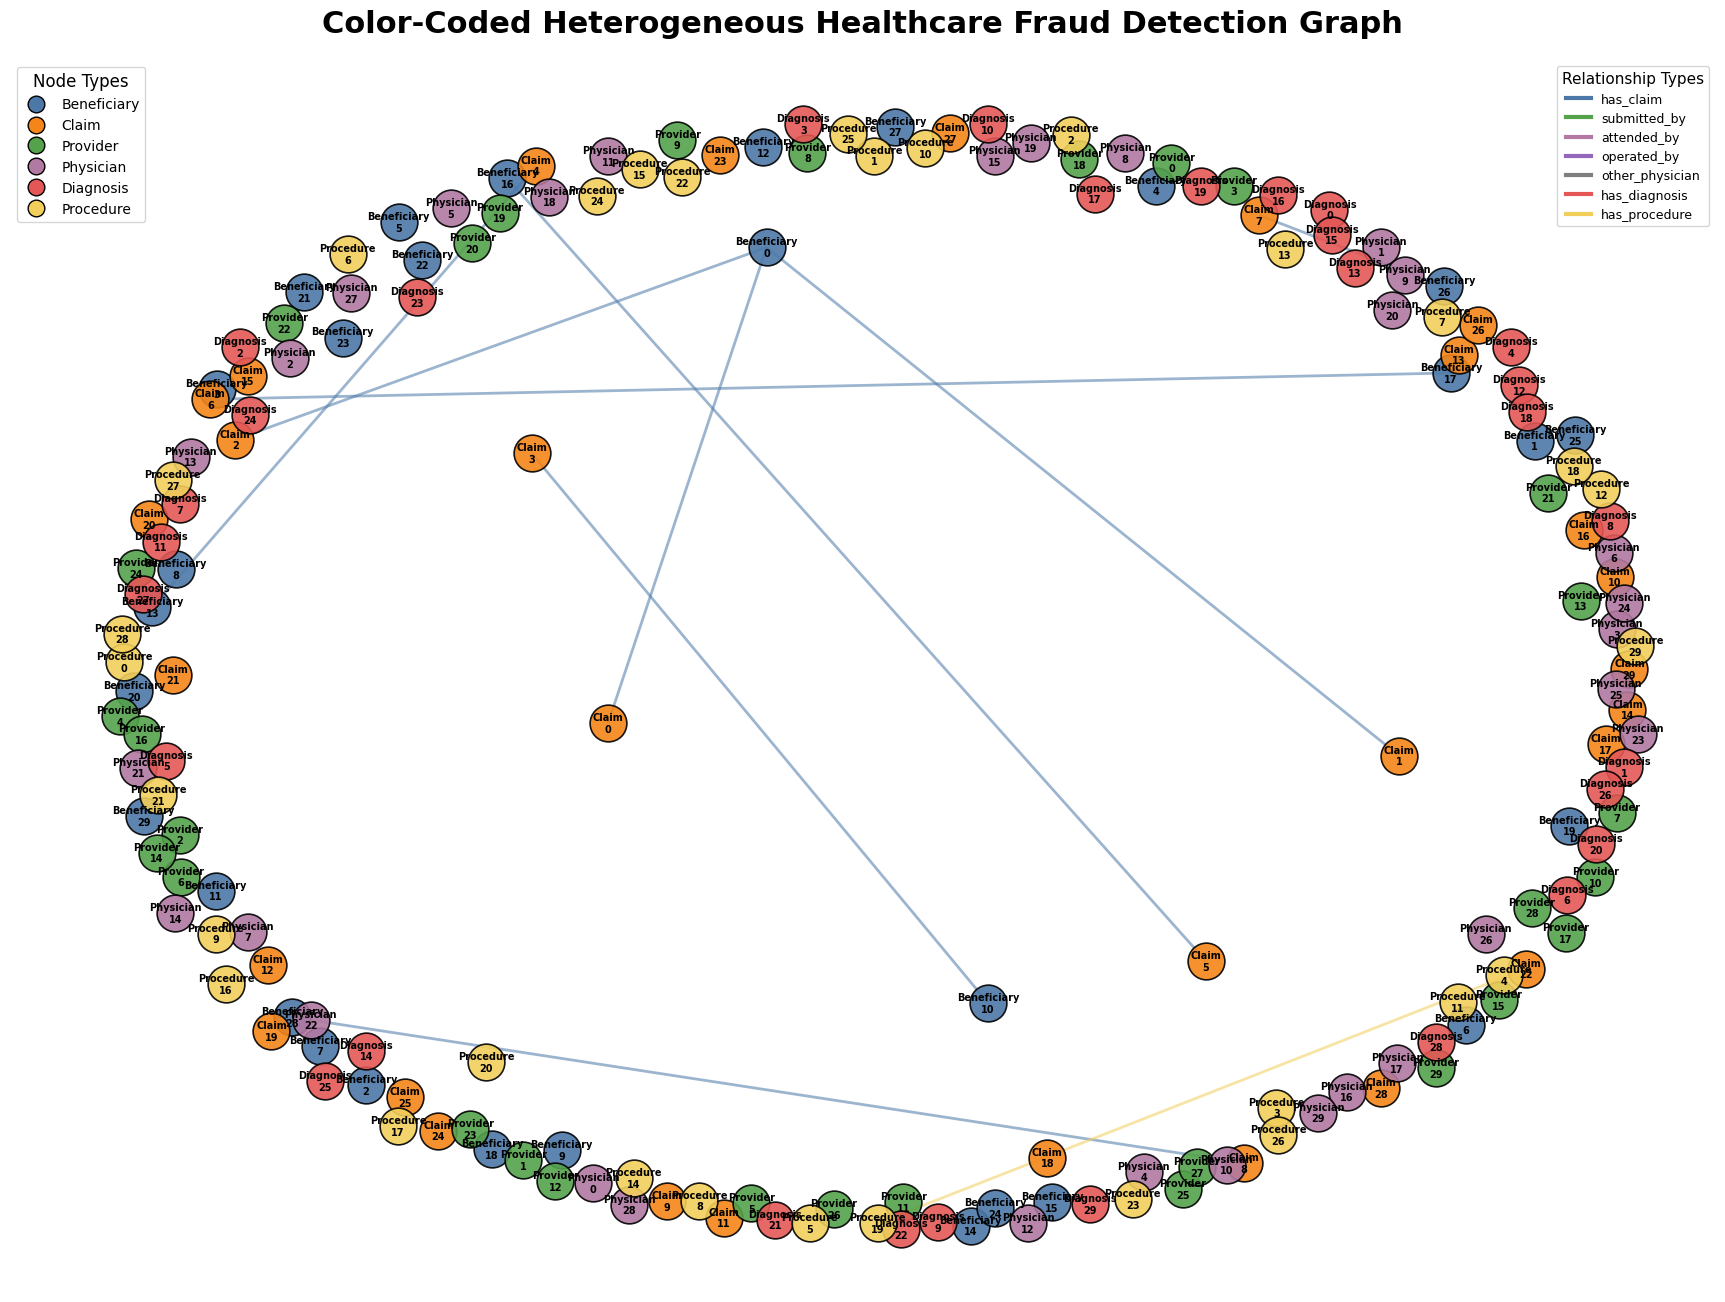


Visualization saved to:
./datasets/graph/graph_visualizations/colorful_heterogeneous_graph.png


In [23]:
# ============================================================
# STEP 03A — COLORFUL HETEROGENEOUS GRAPH VISUALIZATION
# ============================================================

import os
import torch
import networkx as nx
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load heterogeneous graph
# ------------------------------------------------------------

DATA_PATH = "./datasets/graph/hetero_data.pt"
OUTPUT_DIR = "./datasets/graph/graph_visualizations"

os.makedirs(OUTPUT_DIR, exist_ok=True)

data = torch.load(DATA_PATH, weights_only=False)

print("Loaded heterogeneous graph:")
print(data)

# ------------------------------------------------------------
# 2. Node colors
# ------------------------------------------------------------

NODE_COLORS = {
    "beneficiary": "#4C78A8",   # blue
    "claim": "#F58518",         # orange
    "provider": "#54A24B",      # green
    "physician": "#B279A2",     # purple
    "diagnosis": "#E45756",     # red
    "procedure": "#F2CF5B"      # yellow
}

NODE_LABELS = {
    "beneficiary": "Beneficiary",
    "claim": "Claim",
    "provider": "Provider",
    "physician": "Physician",
    "diagnosis": "Diagnosis",
    "procedure": "Procedure"
}

# ------------------------------------------------------------
# 3. Edge colors
# ------------------------------------------------------------

EDGE_COLORS = {
    "has_claim": "#4C78A8",
    "submitted_by": "#54A24B",
    "attended_by": "#B279A2",
    "operated_by": "#9467BD",
    "other_physician": "#7F7F7F",
    "has_diagnosis": "#E45756",
    "has_procedure": "#F2CF5B"
}

# ------------------------------------------------------------
# 4. Maximum nodes per type
# ------------------------------------------------------------

MAX_NODES_PER_TYPE = 30

# ------------------------------------------------------------
# 5. Create NetworkX graph
# ------------------------------------------------------------

G = nx.Graph()

selected_nodes = {}

for node_type in NODE_LABELS.keys():

    if node_type not in data.node_types:
        continue

    num_nodes = data[node_type].num_nodes

    # Sample only a small number for visualization
    num_selected = min(num_nodes, MAX_NODES_PER_TYPE)

    selected = list(range(num_selected))

    selected_nodes[node_type] = set(selected)

    for node_id in selected:

        graph_node = f"{node_type}_{node_id}"

        G.add_node(
            graph_node,
            node_type=node_type,
            node_id=node_id
        )

print("\nNodes added:")
print(G.number_of_nodes())

# ------------------------------------------------------------
# 6. Add heterogeneous edges
# ------------------------------------------------------------

relationship_types = [
    ("beneficiary", "has_claim", "claim"),
    ("claim", "submitted_by", "provider"),
    ("claim", "attended_by", "physician"),
    ("claim", "operated_by", "physician"),
    ("claim", "other_physician", "physician"),
    ("claim", "has_diagnosis", "diagnosis"),
    ("claim", "has_procedure", "procedure")
]

for src_type, relation, dst_type in relationship_types:

    edge_type = (src_type, relation, dst_type)

    if edge_type not in data.edge_types:
        continue

    edge_index = data[edge_type].edge_index

    src_nodes = edge_index[0].cpu().numpy()
    dst_nodes = edge_index[1].cpu().numpy()

    for src, dst in zip(src_nodes, dst_nodes):

        if (
            src in selected_nodes.get(src_type, set())
            and dst in selected_nodes.get(dst_type, set())
        ):

            src_name = f"{src_type}_{src}"
            dst_name = f"{dst_type}_{dst}"

            G.add_edge(
                src_name,
                dst_name,
                relation=relation
            )

print("Edges added:")
print(G.number_of_edges())

# ------------------------------------------------------------
# 7. Layout
# ------------------------------------------------------------

print("\nCalculating graph layout...")

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5,
    iterations=100
)

# ------------------------------------------------------------
# 8. Plot
# ------------------------------------------------------------

plt.figure(figsize=(22, 16))

# ------------------------------------------------------------
# Draw each node type separately
# ------------------------------------------------------------

for node_type, color in NODE_COLORS.items():

    nodes = [
        node
        for node in G.nodes
        if G.nodes[node]["node_type"] == node_type
    ]

    if len(nodes) == 0:
        continue

    nx.draw_networkx_nodes(
        G,
        pos,
        nodelist=nodes,
        node_color=color,
        node_size=700,
        alpha=0.90,
        edgecolors="black",
        linewidths=1.2,
        node_shape="o"
    )

# ------------------------------------------------------------
# 9. Draw edges according to relationship
# ------------------------------------------------------------

for relation, color in EDGE_COLORS.items():

    edges = [
        (u, v)
        for u, v, attributes in G.edges(data=True)
        if attributes.get("relation") == relation
    ]

    if len(edges) == 0:
        continue

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=edges,
        edge_color=color,
        width=2.0,
        alpha=0.55
    )

# ------------------------------------------------------------
# 10. Labels
# ------------------------------------------------------------

labels = {}

for node in G.nodes:

    node_type = G.nodes[node]["node_type"]
    node_id = G.nodes[node]["node_id"]

    labels[node] = f"{NODE_LABELS[node_type]}\n{node_id}"

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=7,
    font_weight="bold"
)

# ------------------------------------------------------------
# 11. Title
# ------------------------------------------------------------

plt.title(
    "Color-Coded Heterogeneous Healthcare Fraud Detection Graph",
    fontsize=22,
    fontweight="bold",
    pad=20
)

plt.axis("off")

# ------------------------------------------------------------
# 12. Legend for node types
# ------------------------------------------------------------

from matplotlib.lines import Line2D

node_legend = []

for node_type, color in NODE_COLORS.items():

    node_legend.append(
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label=NODE_LABELS[node_type],
            markerfacecolor=color,
            markeredgecolor="black",
            markersize=12
        )
    )

# ------------------------------------------------------------
# 13. Legend for edge types
# ------------------------------------------------------------

edge_legend = []

for relation, color in EDGE_COLORS.items():

    edge_legend.append(
        Line2D(
            [0],
            [0],
            color=color,
            lw=3,
            label=relation
        )
    )

legend1 = plt.legend(
    handles=node_legend,
    title="Node Types",
    loc="upper left",
    fontsize=10,
    title_fontsize=12
)

plt.gca().add_artist(legend1)

plt.legend(
    handles=edge_legend,
    title="Relationship Types",
    loc="upper right",
    fontsize=9,
    title_fontsize=11
)

# ------------------------------------------------------------
# 14. Save
# ------------------------------------------------------------

output_path = os.path.join(
    OUTPUT_DIR,
    "colorful_heterogeneous_graph.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(output_path)

Loading heterogeneous graph...

Loaded graph:
HeteroData(
  beneficiary={ x=[138556, 28] },
  claim={ x=[558211, 4] },
  provider={
    x=[5410, 21],
    y=[5410],
  },
  physician={ x=[100738, 3] },
  diagnosis={ x=[11015, 3] },
  procedure={ x=[1327, 3] },
  (beneficiary, has_claim, claim)={ edge_index=[2, 558211] },
  (claim, belongs_to, beneficiary)={ edge_index=[2, 558211] },
  (claim, submitted_by, provider)={ edge_index=[2, 558211] },
  (provider, submitted_claim, claim)={ edge_index=[2, 558211] },
  (claim, attended_by, physician)={ edge_index=[2, 556703] },
  (physician, attended_claim, claim)={ edge_index=[2, 556703] },
  (claim, operated_by, physician)={ edge_index=[2, 114447] },
  (physician, operated_claim, claim)={ edge_index=[2, 114447] },
  (claim, other_physician, physician)={ edge_index=[2, 199736] },
  (physician, other_claim, claim)={ edge_index=[2, 199736] },
  (claim, has_diagnosis, diagnosis)={ edge_index=[2, 1826583] },
  (diagnosis, diagnosed_claim, claim)={ ed

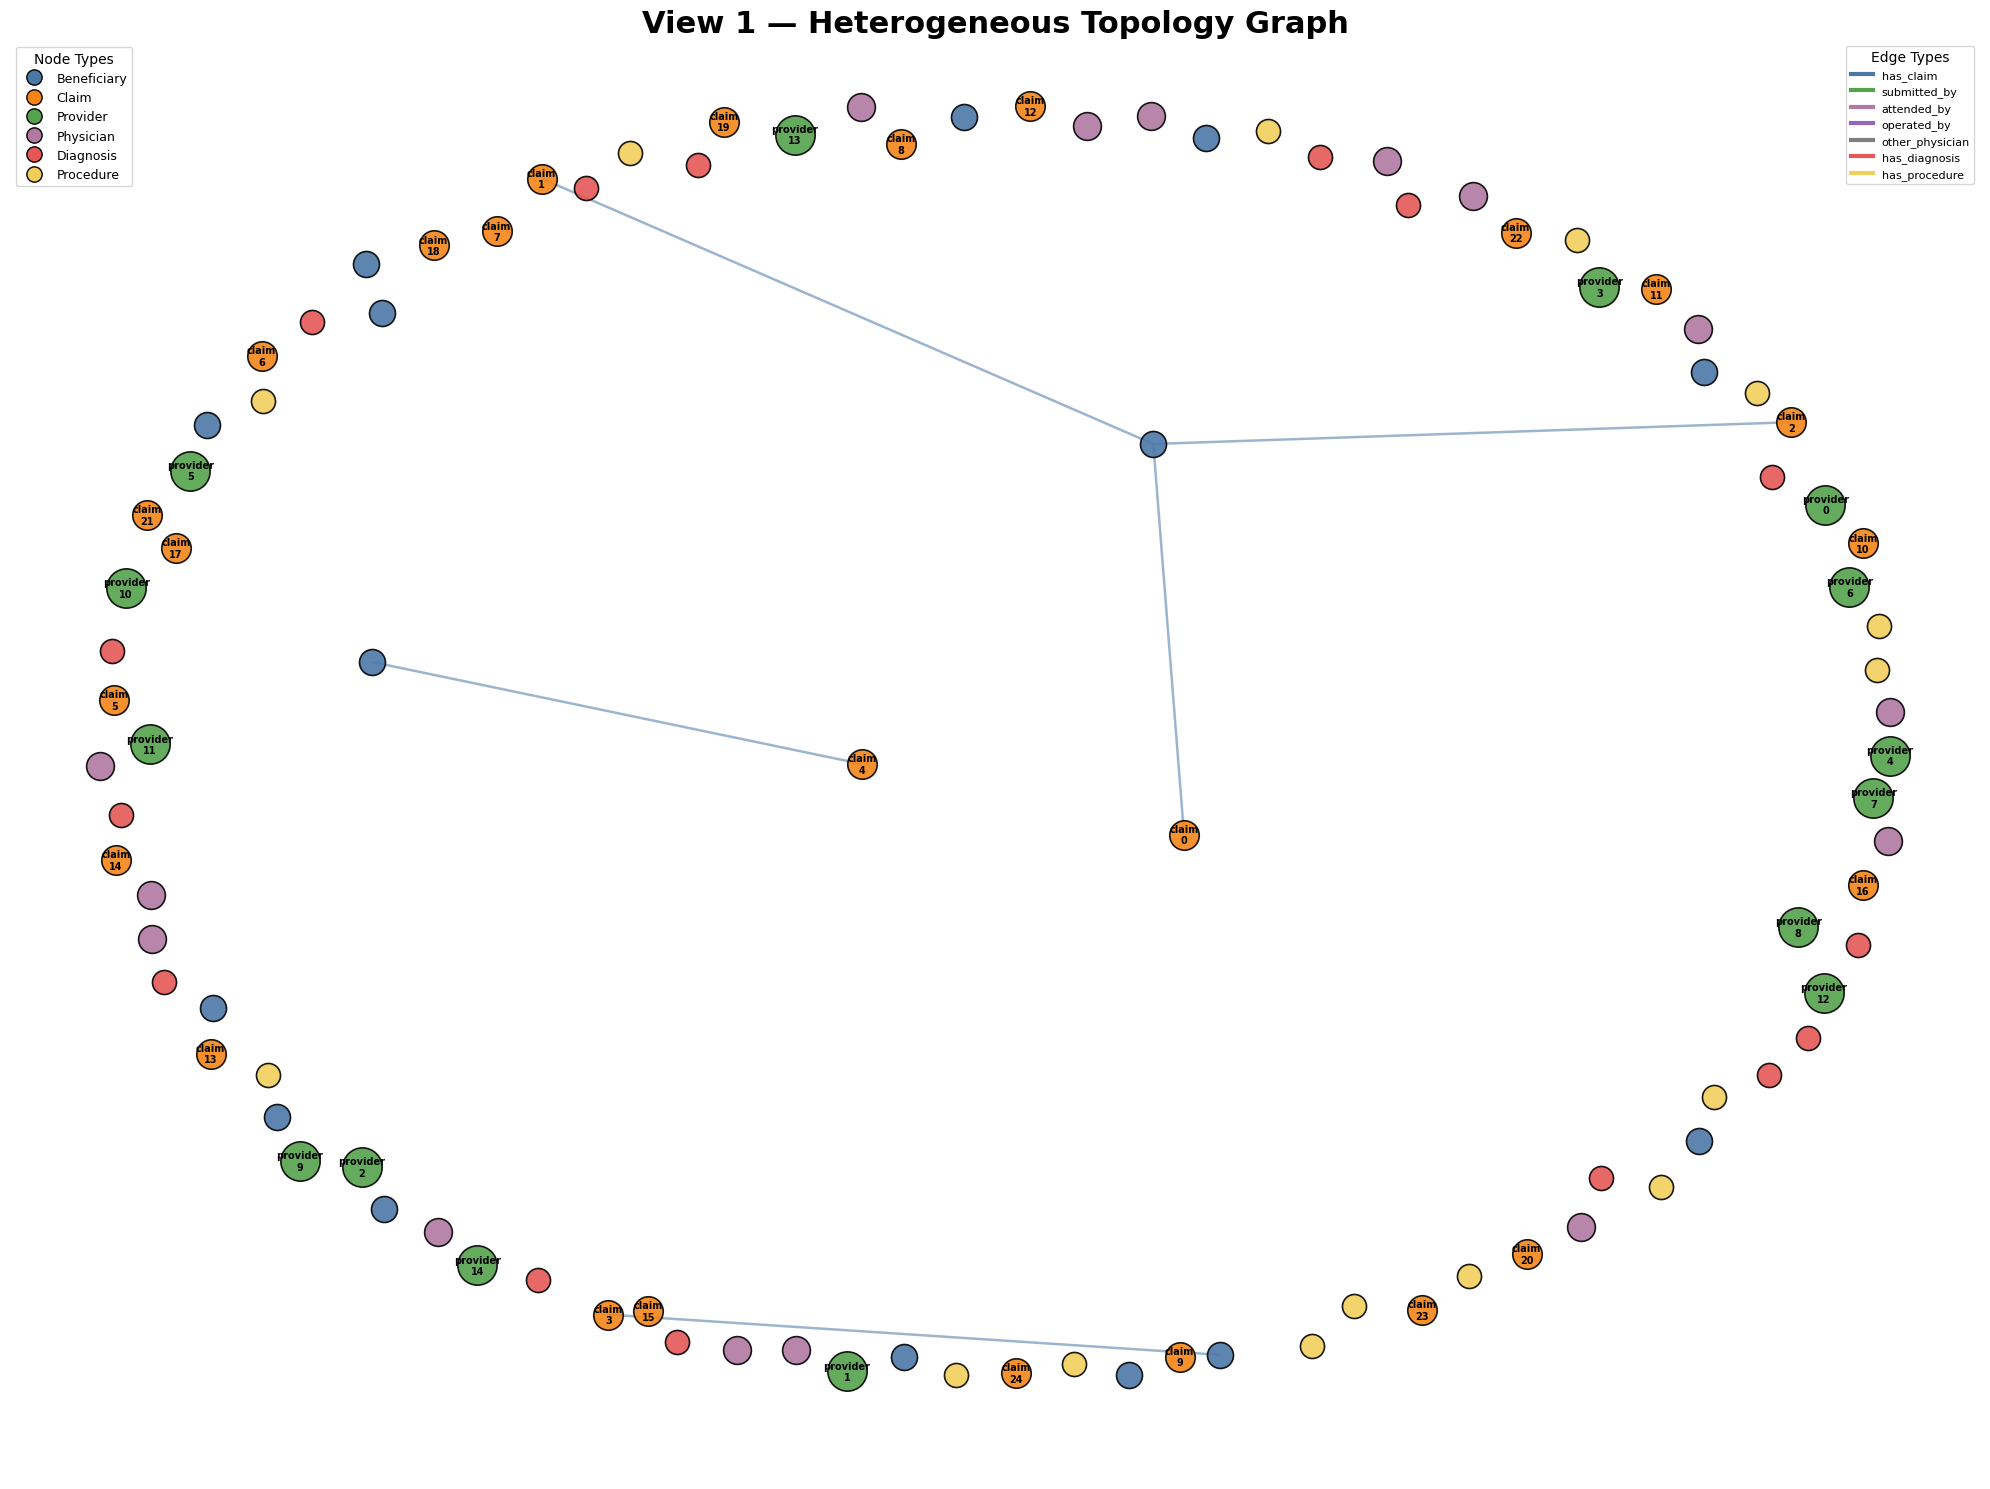

Saved: data/graph_visualizations/view_1_topology_graph.png

VIEW 2 — FEATURE SIMILARITY GRAPH

Feature columns used:
 - Unnamed: 0
 - TotalClaims
 - UniqueBeneficiaries
 - UniqueAttendingPhysicians
 - UniqueOperatingPhysicians
 - UniqueOtherPhysicians
 - TotalReimbursement
 - AverageReimbursement
 - MaximumReimbursement
 - TotalDeductible
 - AverageDeductible
 - AverageClaimDuration
 - MaximumClaimDuration
 - InpatientClaims
 - OutpatientClaims
 - UniqueDiagnoses
 - UniqueProcedures
 - ReimbursementPerClaim
 - DeductiblePerClaim
 - InpatientRatio
 - OutpatientRatio
Feature graph nodes: 5410
Feature graph edges: 19098


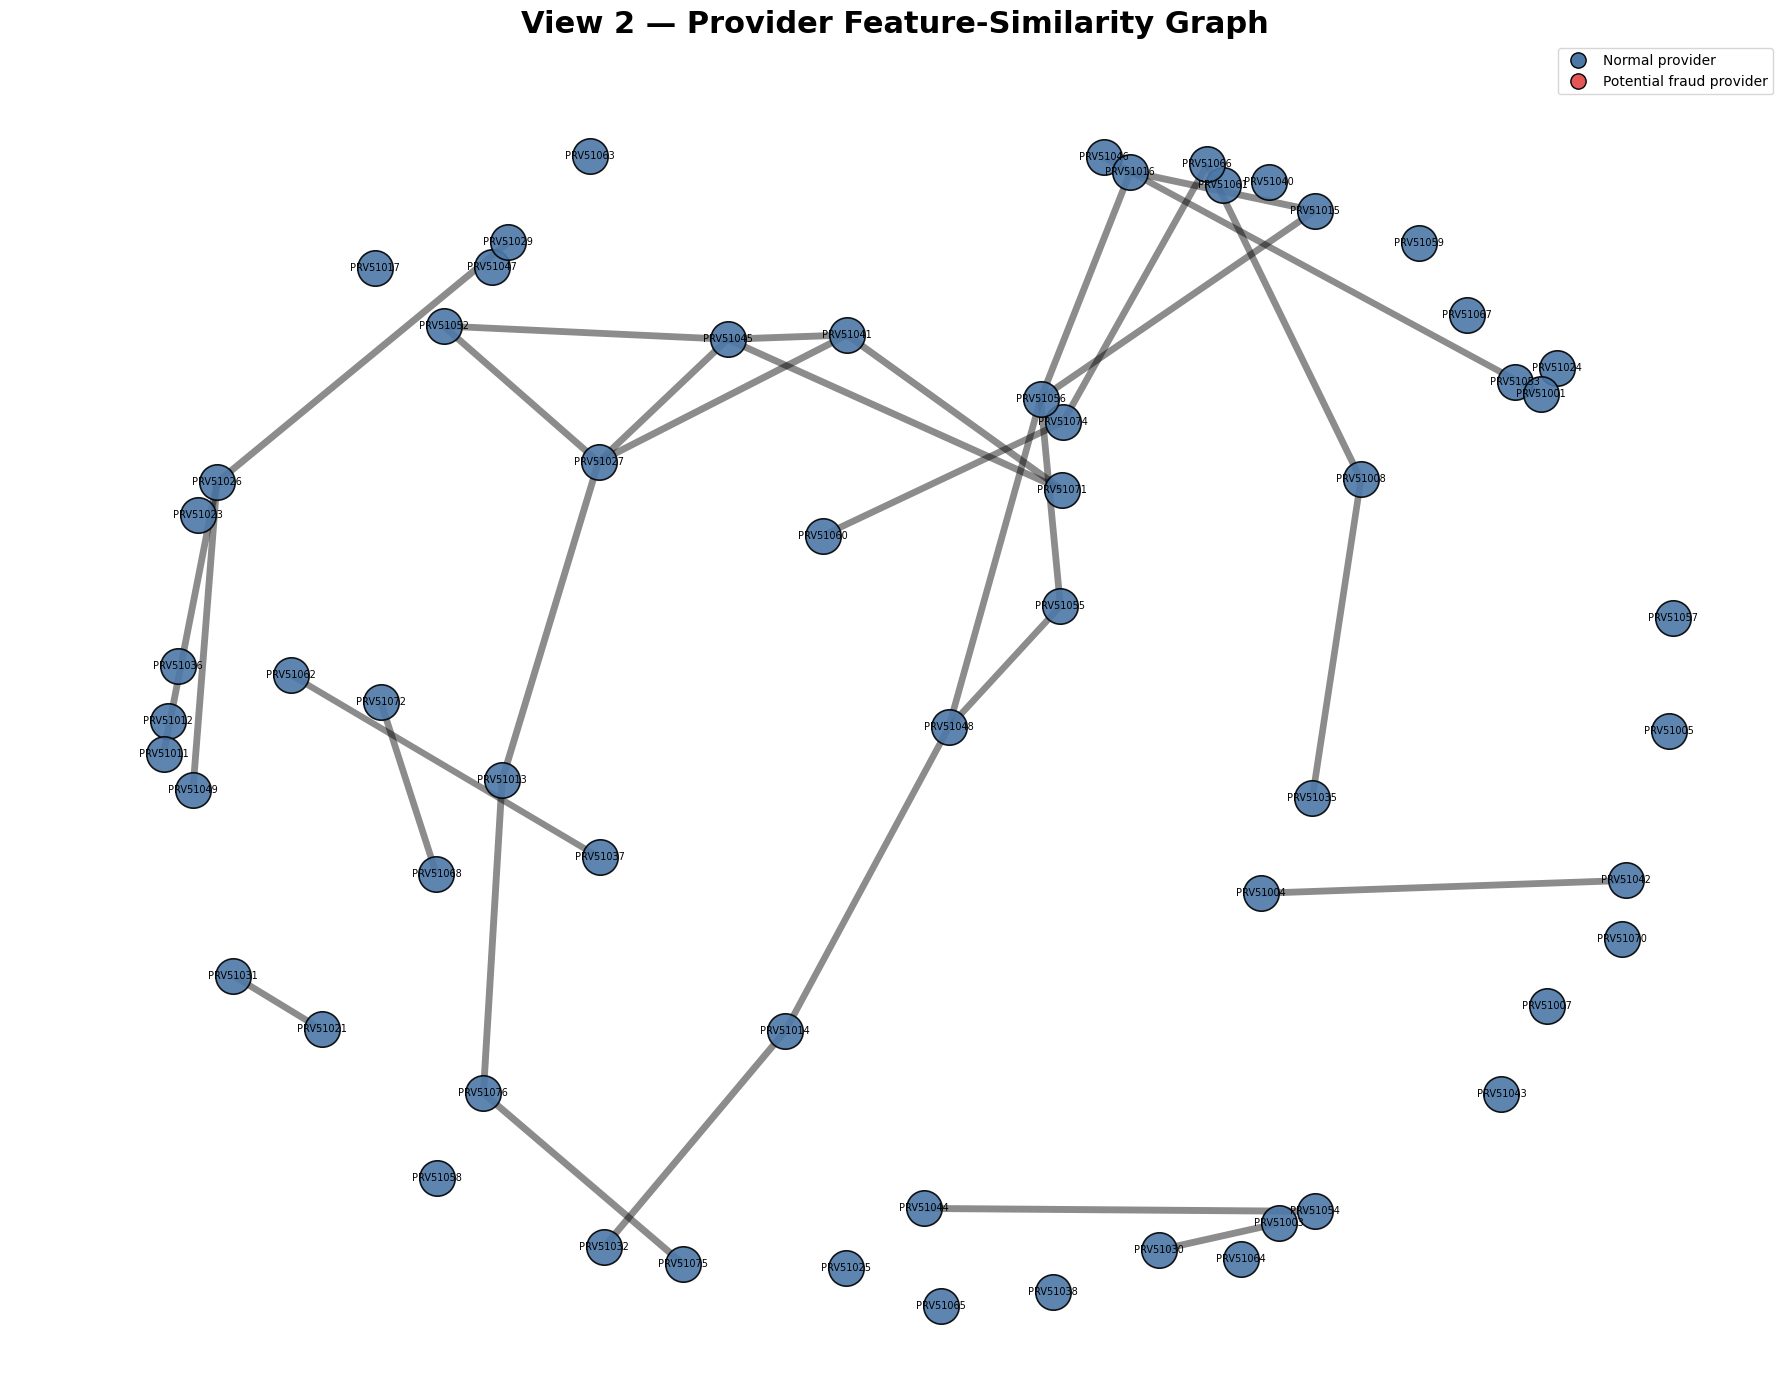

Saved: data/graph_visualizations/view_2_feature_graph.png

VIEW 3 — SEMANTIC GRAPH

Semantic networks:
P-B-P: 10791 nodes, 168104 edges
P-Physician-P: 9338 nodes, 6243 edges
P-Diagnosis-P: 10815 nodes, 13439586 edges
P-Procedure-P: 7431 nodes, 901321 edges

Combined semantic graph: 10820 nodes, 13440654 edges


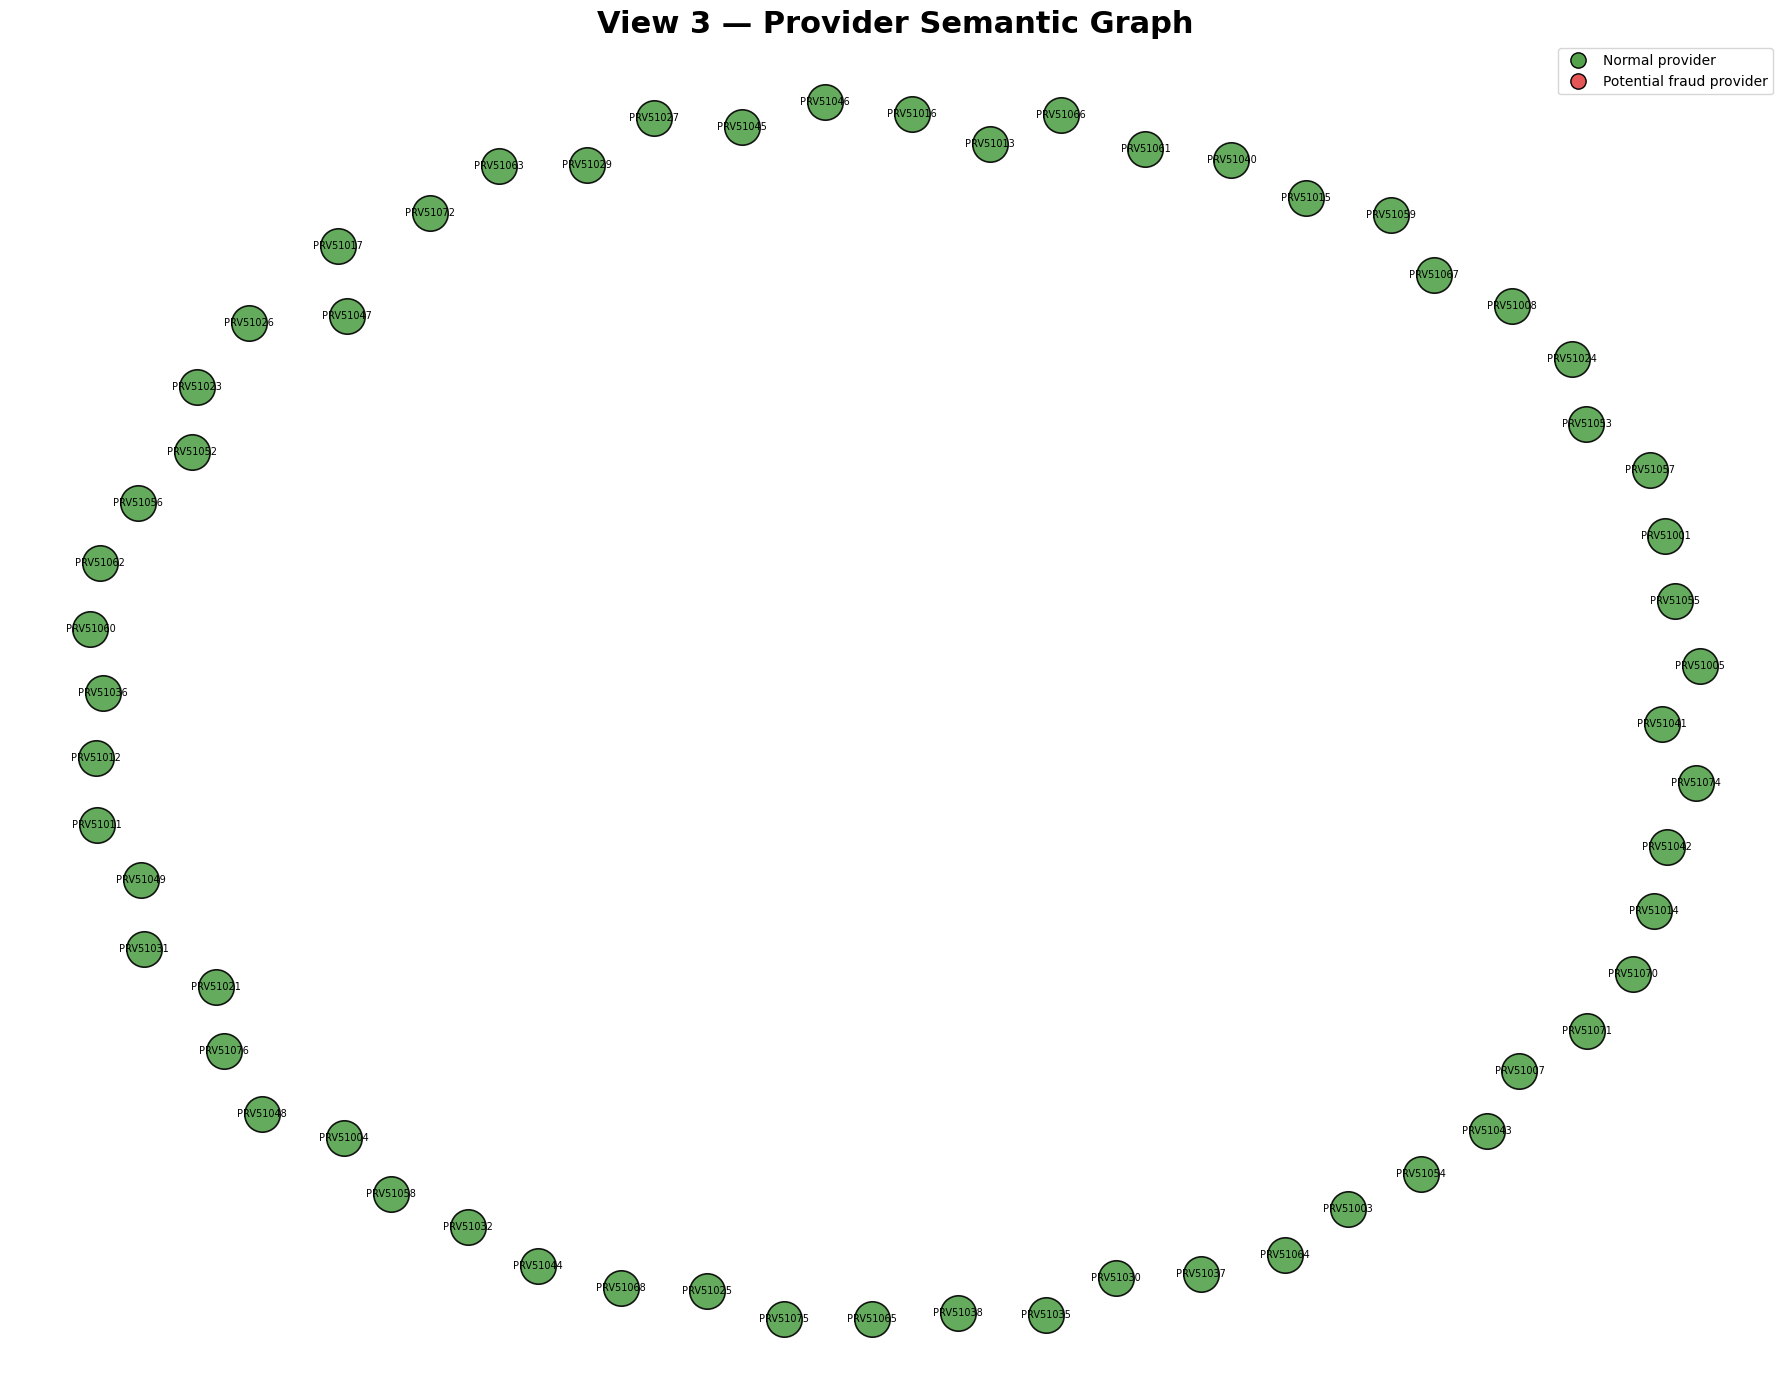

Saved: data/graph_visualizations/view_3_semantic_graph.png

GRAPH SUMMARY

Topology graph: 100 nodes, 5 edges
Feature graph: 5410 nodes, 19098 edges
Semantic graph: 10820 nodes, 13440654 edges

Visualization files:
data/graph_visualizations/view_1_topology_graph.png
data/graph_visualizations/view_2_feature_graph.png
data/graph_visualizations/view_3_semantic_graph.png

Done.


In [24]:
# ============================================================
# STEP 03B — THREE MHGSL GRAPH VIEW VISUALIZATIONS
#
# 1. Topology Graph
# 2. Feature Similarity Graph
# 3. Semantic Graph
#
# Uses outputs from Step 02 + Step 03
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity


# ============================================================
# 1. PATHS
# ============================================================

HETERO_PATH = "./datasets/graph/hetero_data.pt"
FEATURE_PATH = "./datasets/features_const/providers_features.csv"
MAPPING_PATH = "./datasets/graph/node_id_mappings.pt"

OUTPUT_DIR = "data/graph_visualizations"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD DATA
# ============================================================

print("Loading heterogeneous graph...")

data = torch.load(
    HETERO_PATH,
    weights_only=False
)

provider_features = pd.read_csv(FEATURE_PATH)

mappings = torch.load(
    MAPPING_PATH,
    weights_only=False
)

print("\nLoaded graph:")
print(data)

print("\nProvider feature shape:")
print(provider_features.shape)


# ============================================================
# 3. HELPER FUNCTION
# ============================================================

def tensor_to_numpy(x):
    return x.detach().cpu().numpy()


# ============================================================
# ============================================================
# VIEW 1 — TOPOLOGY GRAPH
# ============================================================
# ============================================================

print("\n" + "=" * 60)
print("VIEW 1 — TOPOLOGY GRAPH")
print("=" * 60)


# ------------------------------------------------------------
# Node colors
# ------------------------------------------------------------

NODE_COLORS = {
    "beneficiary": "#4C78A8",
    "claim": "#F58518",
    "provider": "#54A24B",
    "physician": "#B279A2",
    "diagnosis": "#E45756",
    "procedure": "#F2CF5B"
}


NODE_SIZES = {
    "beneficiary": 350,
    "claim": 450,
    "provider": 800,
    "physician": 400,
    "diagnosis": 300,
    "procedure": 300
}


# ------------------------------------------------------------
# Relationship colors
# ------------------------------------------------------------

EDGE_COLORS = {
    "has_claim": "#4C78A8",
    "submitted_by": "#54A24B",
    "attended_by": "#B279A2",
    "operated_by": "#9467BD",
    "other_physician": "#7F7F7F",
    "has_diagnosis": "#E45756",
    "has_procedure": "#F2CF5B"
}


# ------------------------------------------------------------
# Sample nodes
# ------------------------------------------------------------

MAX_NODES = {
    "beneficiary": 15,
    "claim": 25,
    "provider": 15,
    "physician": 15,
    "diagnosis": 15,
    "procedure": 15
}


G_topology = nx.Graph()

selected_nodes = {}


# ------------------------------------------------------------
# Add nodes
# ------------------------------------------------------------

for node_type in NODE_COLORS.keys():

    if node_type not in data.node_types:
        continue

    total_nodes = data[node_type].num_nodes

    n = min(
        total_nodes,
        MAX_NODES[node_type]
    )

    selected = set(range(n))

    selected_nodes[node_type] = selected

    for node_id in selected:

        node_name = f"{node_type}_{node_id}"

        G_topology.add_node(
            node_name,
            node_type=node_type,
            node_id=node_id
        )


# ------------------------------------------------------------
# Relationships
# ------------------------------------------------------------

relationships = [
    ("beneficiary", "has_claim", "claim"),
    ("claim", "submitted_by", "provider"),
    ("claim", "attended_by", "physician"),
    ("claim", "operated_by", "physician"),
    ("claim", "other_physician", "physician"),
    ("claim", "has_diagnosis", "diagnosis"),
    ("claim", "has_procedure", "procedure")
]


# ------------------------------------------------------------
# Add edges
# ------------------------------------------------------------

for src_type, relation, dst_type in relationships:

    edge_type = (
        src_type,
        relation,
        dst_type
    )

    if edge_type not in data.edge_types:
        continue

    edge_index = data[edge_type].edge_index

    src_array = tensor_to_numpy(edge_index[0])
    dst_array = tensor_to_numpy(edge_index[1])

    for src, dst in zip(src_array, dst_array):

        src = int(src)
        dst = int(dst)

        if (
            src in selected_nodes.get(src_type, set())
            and dst in selected_nodes.get(dst_type, set())
        ):

            G_topology.add_edge(
                f"{src_type}_{src}",
                f"{dst_type}_{dst}",
                relation=relation
            )


print(
    "Topology nodes:",
    G_topology.number_of_nodes()
)

print(
    "Topology edges:",
    G_topology.number_of_edges()
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_topology,
    seed=42,
    k=2.0,
    iterations=150
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(20, 15))


for node_type, color in NODE_COLORS.items():

    nodes = [
        n for n in G_topology.nodes
        if G_topology.nodes[n]["node_type"] == node_type
    ]

    if not nodes:
        continue

    nx.draw_networkx_nodes(
        G_topology,
        pos,
        nodelist=nodes,
        node_color=color,
        node_size=NODE_SIZES[node_type],
        edgecolors="black",
        linewidths=1.2,
        alpha=0.9
    )


# ------------------------------------------------------------
# Draw edges
# ------------------------------------------------------------

for relation, color in EDGE_COLORS.items():

    edges = [
        (u, v)
        for u, v, d in G_topology.edges(data=True)
        if d["relation"] == relation
    ]

    if not edges:
        continue

    nx.draw_networkx_edges(
        G_topology,
        pos,
        edgelist=edges,
        edge_color=color,
        width=1.8,
        alpha=0.55
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

labels = {}

for node in G_topology.nodes:

    node_type = G_topology.nodes[node]["node_type"]
    node_id = G_topology.nodes[node]["node_id"]

    # Only label important nodes
    if node_type in ["provider", "claim"]:

        labels[node] = f"{node_type}\n{node_id}"


nx.draw_networkx_labels(
    G_topology,
    pos,
    labels=labels,
    font_size=7,
    font_weight="bold"
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

from matplotlib.lines import Line2D


node_legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color,
        markeredgecolor="black",
        markersize=11,
        label=node_type.capitalize()
    )
    for node_type, color in NODE_COLORS.items()
]


edge_legend = [
    Line2D(
        [0],
        [0],
        color=color,
        lw=3,
        label=relation
    )
    for relation, color in EDGE_COLORS.items()
]


legend1 = plt.legend(
    handles=node_legend,
    title="Node Types",
    loc="upper left",
    fontsize=9
)

plt.gca().add_artist(legend1)

plt.legend(
    handles=edge_legend,
    title="Edge Types",
    loc="upper right",
    fontsize=8
)


plt.title(
    "View 1 — Heterogeneous Topology Graph",
    fontsize=22,
    fontweight="bold"
)

plt.axis("off")

plt.tight_layout()

topology_path = os.path.join(
    OUTPUT_DIR,
    "view_1_topology_graph.png"
)

plt.savefig(
    topology_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", topology_path)


# ============================================================
# ============================================================
# VIEW 2 — FEATURE SIMILARITY GRAPH
# ============================================================
# ============================================================

print("\n" + "=" * 60)
print("VIEW 2 — FEATURE SIMILARITY GRAPH")
print("=" * 60)


# ------------------------------------------------------------
# Identify provider ID column
# ------------------------------------------------------------

if "Provider" not in provider_features.columns:

    raise ValueError(
        "Provider column not found in provider_features.csv"
    )


# ------------------------------------------------------------
# Numeric provider features
# ------------------------------------------------------------

exclude_columns = [
    "Provider",
    "PotentialFraud"
]


numeric_columns = provider_features.select_dtypes(
    include=[np.number]
).columns.tolist()


feature_columns = [
    c for c in numeric_columns
    if c not in exclude_columns
]


print("\nFeature columns used:")

for col in feature_columns:
    print(" -", col)


X = provider_features[feature_columns].copy()


# ------------------------------------------------------------
# Handle invalid values
# ------------------------------------------------------------

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(
    X.median()
)


# ------------------------------------------------------------
# Standardization
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ------------------------------------------------------------
# KNN feature graph
# ------------------------------------------------------------

K = 5

n_neighbors = min(
    K + 1,
    len(provider_features)
)


knn = NearestNeighbors(
    n_neighbors=n_neighbors,
    metric="cosine"
)

knn.fit(X_scaled)


distances, indices = knn.kneighbors(
    X_scaled
)


G_feature = nx.Graph()


# ------------------------------------------------------------
# Add providers
# ------------------------------------------------------------

for i, provider in enumerate(
    provider_features["Provider"]
):

    G_feature.add_node(
        provider,
        provider_index=i
    )


# ------------------------------------------------------------
# Add similarity edges
# ------------------------------------------------------------

for i in range(len(provider_features)):

    for j in range(1, n_neighbors):

        neighbor = indices[i, j]

        distance = distances[i, j]

        similarity = 1.0 - distance

        if similarity > 0:

            provider_i = provider_features.iloc[i]["Provider"]
            provider_j = provider_features.iloc[neighbor]["Provider"]

            G_feature.add_edge(
                provider_i,
                provider_j,
                weight=similarity
            )


print(
    "Feature graph nodes:",
    G_feature.number_of_nodes()
)

print(
    "Feature graph edges:",
    G_feature.number_of_edges()
)


# ------------------------------------------------------------
# Visualize a sample
# ------------------------------------------------------------

MAX_FEATURE_NODES = 60

feature_nodes = list(
    G_feature.nodes
)[:MAX_FEATURE_NODES]

G_feature_sample = G_feature.subgraph(
    feature_nodes
).copy()


pos_feature = nx.spring_layout(
    G_feature_sample,
    seed=42,
    k=1.5,
    iterations=150
)


plt.figure(figsize=(18, 14))


# ------------------------------------------------------------
# Draw edges
# ------------------------------------------------------------

edges = G_feature_sample.edges(
    data=True
)

edge_widths = [
    1 + 4 * d.get("weight", 0)
    for _, _, d in edges
]


nx.draw_networkx_edges(
    G_feature_sample,
    pos_feature,
    width=edge_widths,
    alpha=0.45
)


# ------------------------------------------------------------
# Draw providers
# ------------------------------------------------------------

nx.draw_networkx_nodes(
    G_feature_sample,
    pos_feature,
    node_color="#4C78A8",
    node_size=650,
    edgecolors="black",
    linewidths=1.2,
    alpha=0.9
)


# ------------------------------------------------------------
# Fraud colors
# ------------------------------------------------------------

fraud_lookup = dict(
    zip(
        provider_features["Provider"],
        provider_features["PotentialFraud"]
    )
)


fraud_nodes = [
    node
    for node in G_feature_sample.nodes
    if str(fraud_lookup.get(node, "No")) == "Yes"
]


if fraud_nodes:

    nx.draw_networkx_nodes(
        G_feature_sample,
        pos_feature,
        nodelist=fraud_nodes,
        node_color="#E45756",
        node_size=800,
        edgecolors="black",
        linewidths=2
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

nx.draw_networkx_labels(
    G_feature_sample,
    pos_feature,
    font_size=7
)


plt.title(
    "View 2 — Provider Feature-Similarity Graph",
    fontsize=22,
    fontweight="bold"
)

plt.axis("off")


feature_legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#4C78A8",
        markeredgecolor="black",
        markersize=11,
        label="Normal provider"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#E45756",
        markeredgecolor="black",
        markersize=11,
        label="Potential fraud provider"
    )
]


plt.legend(
    handles=feature_legend,
    loc="upper right"
)

plt.tight_layout()


feature_path = os.path.join(
    OUTPUT_DIR,
    "view_2_feature_graph.png"
)

plt.savefig(
    feature_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", feature_path)


# ============================================================
# ============================================================
# VIEW 3 — SEMANTIC GRAPH
# ============================================================
# ============================================================

print("\n" + "=" * 60)
print("VIEW 3 — SEMANTIC GRAPH")
print("=" * 60)


# ------------------------------------------------------------
# Build provider → entity relationships
# ------------------------------------------------------------

def build_provider_entity_pairs(
    claim_to_provider,
    claim_to_entity
):

    provider_entity = []

    for claim, provider in claim_to_provider.items():

        entities = claim_to_entity.get(
            claim,
            set()
        )

        for entity in entities:

            provider_entity.append(
                (provider, entity)
            )

    return provider_entity


# ------------------------------------------------------------
# Extract mappings from HeteroData
# ------------------------------------------------------------

def get_edge_pairs(edge_type):

    if edge_type not in data.edge_types:
        return []

    edge_index = data[edge_type].edge_index

    src = tensor_to_numpy(
        edge_index[0]
    )

    dst = tensor_to_numpy(
        edge_index[1]
    )

    return list(
        zip(
            src.astype(int),
            dst.astype(int)
        )
    )


# ------------------------------------------------------------
# Claim → Provider
# ------------------------------------------------------------

claim_provider_pairs = get_edge_pairs(
    ("claim", "submitted_by", "provider")
)

claim_to_provider = {
    int(claim): int(provider)
    for claim, provider in claim_provider_pairs
}


# ------------------------------------------------------------
# Claim → Beneficiary
# ------------------------------------------------------------

claim_beneficiary_pairs = get_edge_pairs(
    ("claim", "belongs_to", "beneficiary")
)

claim_to_beneficiary = {}

for claim, beneficiary in claim_beneficiary_pairs:

    claim_to_beneficiary.setdefault(
        claim,
        set()
    ).add(beneficiary)


# ------------------------------------------------------------
# Claim → Physician
# ------------------------------------------------------------

physician_claim_pairs = []

for relation in [
    "attended_claim",
    "operated_claim",
    "other_claim"
]:

    edge_type = (
        "physician",
        relation,
        "claim"
    )

    if edge_type in data.edge_types:

        pairs = get_edge_pairs(
            edge_type
        )

        for physician, claim in pairs:

            physician_claim_pairs.append(
                (claim, physician)
            )


claim_to_physician = {}

for claim, physician in physician_claim_pairs:

    claim_to_physician.setdefault(
        claim,
        set()
    ).add(physician)


# ------------------------------------------------------------
# Claim → Diagnosis
# ------------------------------------------------------------

diagnosis_claim_pairs = get_edge_pairs(
    ("diagnosis", "diagnosed_claim", "claim")
)

claim_to_diagnosis = {}

for diagnosis, claim in diagnosis_claim_pairs:

    claim_to_diagnosis.setdefault(
        claim,
        set()
    ).add(diagnosis)


# ------------------------------------------------------------
# Claim → Procedure
# ------------------------------------------------------------

procedure_claim_pairs = get_edge_pairs(
    ("procedure", "used_in_claim", "claim")
)

claim_to_procedure = {}

for procedure, claim in procedure_claim_pairs:

    claim_to_procedure.setdefault(
        claim,
        set()
    ).add(procedure)


# ============================================================
# Create provider-provider semantic networks
# ============================================================

semantic_networks = {}


def create_provider_projection(
    claim_to_provider,
    claim_to_entity
):

    provider_entity_pairs = (
        build_provider_entity_pairs(
            claim_to_provider,
            claim_to_entity
        )
    )

    entity_to_providers = {}

    for provider, entity in provider_entity_pairs:

        entity_to_providers.setdefault(
            entity,
            set()
        ).add(provider)


    G = nx.Graph()


    # Add providers
    for provider in provider_features["Provider"]:

        G.add_node(provider)


    # Connect providers sharing an entity
    for entity, providers in entity_to_providers.items():

        providers = list(providers)

        for i in range(len(providers)):

            for j in range(i + 1, len(providers)):

                p1 = providers[i]
                p2 = providers[j]

                if G.has_edge(p1, p2):

                    G[p1][p2]["weight"] += 1

                else:

                    G.add_edge(
                        p1,
                        p2,
                        weight=1
                    )

    return G


# ------------------------------------------------------------
# P-B-P
# ------------------------------------------------------------

semantic_networks["P-B-P"] = (
    create_provider_projection(
        claim_to_provider,
        claim_to_beneficiary
    )
)


# ------------------------------------------------------------
# P-Physician-P
# ------------------------------------------------------------

semantic_networks["P-Physician-P"] = (
    create_provider_projection(
        claim_to_provider,
        claim_to_physician
    )
)


# ------------------------------------------------------------
# P-Diagnosis-P
# ------------------------------------------------------------

semantic_networks["P-Diagnosis-P"] = (
    create_provider_projection(
        claim_to_provider,
        claim_to_diagnosis
    )
)


# ------------------------------------------------------------
# P-Procedure-P
# ------------------------------------------------------------

semantic_networks["P-Procedure-P"] = (
    create_provider_projection(
        claim_to_provider,
        claim_to_procedure
    )
)


# ============================================================
# Combine semantic networks
# ============================================================

G_semantic = nx.Graph()


for provider in provider_features["Provider"]:

    G_semantic.add_node(provider)


for network_name, network in semantic_networks.items():

    for u, v, attributes in network.edges(
        data=True
    ):

        weight = attributes.get(
            "weight",
            1
        )

        if G_semantic.has_edge(u, v):

            G_semantic[u][v]["weight"] += weight

        else:

            G_semantic.add_edge(
                u,
                v,
                weight=weight,
                relations=[network_name]
            )


print("\nSemantic networks:")

for name, network in semantic_networks.items():

    print(
        f"{name}: "
        f"{network.number_of_nodes()} nodes, "
        f"{network.number_of_edges()} edges"
    )


print(
    "\nCombined semantic graph:",
    G_semantic.number_of_nodes(),
    "nodes,",
    G_semantic.number_of_edges(),
    "edges"
)


# ============================================================
# Sample semantic graph for visualization
# ============================================================

MAX_SEMANTIC_NODES = 60

semantic_nodes = list(
    G_semantic.nodes
)[:MAX_SEMANTIC_NODES]


G_semantic_sample = G_semantic.subgraph(
    semantic_nodes
).copy()


pos_semantic = nx.spring_layout(
    G_semantic_sample,
    seed=42,
    k=1.5,
    iterations=150
)


plt.figure(figsize=(18, 14))


# ------------------------------------------------------------
# Edge weights
# ------------------------------------------------------------

semantic_edge_widths = []

for _, _, d in G_semantic_sample.edges(
    data=True
):

    weight = d.get(
        "weight",
        1
    )

    semantic_edge_widths.append(
        min(6, 0.8 + np.log1p(weight))
    )


nx.draw_networkx_edges(
    G_semantic_sample,
    pos_semantic,
    width=semantic_edge_widths,
    alpha=0.45
)


# ------------------------------------------------------------
# Provider nodes
# ------------------------------------------------------------

nx.draw_networkx_nodes(
    G_semantic_sample,
    pos_semantic,
    node_color="#54A24B",
    node_size=650,
    edgecolors="black",
    linewidths=1.2,
    alpha=0.9
)


# ------------------------------------------------------------
# Fraud providers
# ------------------------------------------------------------

fraud_nodes_semantic = [
    node
    for node in G_semantic_sample.nodes
    if str(fraud_lookup.get(node, "No")) == "Yes"
]


if fraud_nodes_semantic:

    nx.draw_networkx_nodes(
        G_semantic_sample,
        pos_semantic,
        nodelist=fraud_nodes_semantic,
        node_color="#E45756",
        node_size=850,
        edgecolors="black",
        linewidths=2
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

nx.draw_networkx_labels(
    G_semantic_sample,
    pos_semantic,
    font_size=7
)


plt.title(
    "View 3 — Provider Semantic Graph",
    fontsize=22,
    fontweight="bold"
)

plt.axis("off")


semantic_legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#54A24B",
        markeredgecolor="black",
        markersize=11,
        label="Normal provider"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#E45756",
        markeredgecolor="black",
        markersize=11,
        label="Potential fraud provider"
    )
]


plt.legend(
    handles=semantic_legend,
    loc="upper right"
)

plt.tight_layout()


semantic_path = os.path.join(
    OUTPUT_DIR,
    "view_3_semantic_graph.png"
)

plt.savefig(
    semantic_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", semantic_path)


# ============================================================
# 4. SAVE GRAPH STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("GRAPH SUMMARY")
print("=" * 60)

print(
    "\nTopology graph:",
    G_topology.number_of_nodes(),
    "nodes,",
    G_topology.number_of_edges(),
    "edges"
)

print(
    "Feature graph:",
    G_feature.number_of_nodes(),
    "nodes,",
    G_feature.number_of_edges(),
    "edges"
)

print(
    "Semantic graph:",
    G_semantic.number_of_nodes(),
    "nodes,",
    G_semantic.number_of_edges(),
    "edges"
)

print("\nVisualization files:")

print(topology_path)
print(feature_path)
print(semantic_path)

print("\nDone.")

In [25]:
# ...existing code... (insert this cell after STEP 03 graph construction)

import copy

import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from torch_geometric.nn import HeteroConv, SAGEConv


# Use the HeteroData object created in STEP 03.
# If running this cell in a fresh kernel, load the saved graph first:
# data = torch.load("./datasets/graph/hetero_data.pt", weights_only=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = data.to(device)

labels = data["provider"].y.long()
provider_indices = torch.arange(labels.numel()).cpu().numpy()
label_array = labels.cpu().numpy()

train_indices, test_indices = train_test_split(
    provider_indices,
    test_size=0.20,
    random_state=42,
    stratify=label_array,
)

train_indices, val_indices = train_test_split(
    train_indices,
    test_size=0.20,
    random_state=42,
    stratify=label_array[train_indices],
)

train_indices = torch.as_tensor(train_indices, device=device)
val_indices = torch.as_tensor(val_indices, device=device)
test_indices = torch.as_tensor(test_indices, device=device)


class FraudGNN(torch.nn.Module):
    """One heterogeneous GraphSAGE layer and a provider fraud classifier."""

    def __init__(self, metadata, hidden_channels=64, dropout=0.3):
        super().__init__()
        self.conv = HeteroConv(
            {
                edge_type: SAGEConv((-1, -1), hidden_channels)
                for edge_type in metadata[1]
            },
            aggr="sum",
        )
        self.dropout = dropout
        self.classifier = torch.nn.Linear(hidden_channels, 2)

    def forward(self, graph):
        embeddings = self.conv(graph.x_dict, graph.edge_index_dict)
        provider_embeddings = F.relu(embeddings["provider"])
        provider_embeddings = F.dropout(
            provider_embeddings,
            p=self.dropout,
            training=self.training,
        )
        return self.classifier(provider_embeddings)


model = FraudGNN(data.metadata()).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)

class_counts = torch.bincount(labels[train_indices], minlength=2).float()
class_weights = class_counts.sum() / (2 * class_counts.clamp(min=1))
class_weights = class_weights.to(device)

best_val_f1 = -1.0
best_state = None

for epoch in range(1, 101):
    model.train()
    optimizer.zero_grad()

    logits = model(data)
    loss = F.cross_entropy(
        logits[train_indices],
        labels[train_indices],
        weight=class_weights,
    )
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_predictions = model(data)[val_indices].argmax(dim=1)
        val_f1 = f1_score(
            labels[val_indices].cpu(),
            val_predictions.cpu(),
            zero_division=0,
        )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"loss={loss.item():.4f} | "
            f"validation F1={val_f1:.4f}"
        )

if best_state is not None:
    model.load_state_dict(best_state)

model.eval()
with torch.no_grad():
    test_logits = model(data)[test_indices]
    test_predictions = test_logits.argmax(dim=1)
    test_probabilities = test_logits.softmax(dim=1)[:, 1]

test_labels = labels[test_indices].cpu().numpy()
test_predictions = test_predictions.cpu().numpy()
test_probabilities = test_probabilities.cpu().numpy()

print(f"Test accuracy: {accuracy_score(test_labels, test_predictions):.4f}")
print(f"Test fraud F1: {f1_score(test_labels, test_predictions, zero_division=0):.4f}")

if len(set(test_labels)) == 2:
    print(f"Test ROC-AUC: {roc_auc_score(test_labels, test_probabilities):.4f}")

Epoch 010 | loss=5426.3604 | validation F1=0.4646
Epoch 020 | loss=6042.2876 | validation F1=0.5263
Epoch 030 | loss=4272.0747 | validation F1=0.4596
Epoch 040 | loss=3265.7407 | validation F1=0.5797
Epoch 050 | loss=2192.5903 | validation F1=0.4928
Epoch 060 | loss=1697.2030 | validation F1=0.5036
Epoch 070 | loss=1328.7216 | validation F1=0.5130
Epoch 080 | loss=720.0244 | validation F1=0.5092
Epoch 090 | loss=432.7598 | validation F1=0.5094
Epoch 100 | loss=284.1003 | validation F1=0.5455
Test accuracy: 0.9048
Test fraud F1: 0.6171
Test ROC-AUC: 0.8676


In [26]:
import copy

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import HeteroConv, TransformerConv

torch.manual_seed(42)

# Keep the full graph on CPU; only sampled batches are moved to the GPU.
graph = torch.load("./datasets/graph/hetero_data.pt", map_location="cpu", weights_only=False)
labels = graph["provider"].y.long()
provider_indices = np.arange(labels.numel())
label_array = labels.numpy()

train_idx, test_idx = train_test_split(
    provider_indices, test_size=0.20, random_state=42, stratify=label_array
)
train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=42,
    stratify=label_array[train_idx],
)

train_idx = torch.as_tensor(train_idx, dtype=torch.long)
val_idx = torch.as_tensor(val_idx, dtype=torch.long)
test_idx = torch.as_tensor(test_idx, dtype=torch.long)

# Limit sampled neighbors to control memory use. Reduce these values further if needed.
fanouts = {edge_type: [5, 3] for edge_type in graph.edge_types}
batch_size = 64

train_loader = NeighborLoader(
    graph,
    input_nodes=("provider", train_idx),
    num_neighbors=fanouts,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
)
val_loader = NeighborLoader(
    graph,
    input_nodes=("provider", val_idx),
    num_neighbors=fanouts,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)
test_loader = NeighborLoader(
    graph,
    input_nodes=("provider", test_idx),
    num_neighbors=fanouts,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)


class HINormerStyle(torch.nn.Module):
    """Memory-friendlier heterogeneous transformer for sampled graph batches."""

    def __init__(self, graph, hidden_channels=32, heads=1, dropout=0.3):
        super().__init__()
        self.dropout = dropout
        self.input_projection = torch.nn.ModuleDict({
            node_type: torch.nn.Linear(graph[node_type].x.size(-1), hidden_channels)
            for node_type in graph.node_types
        })
        self.layers = torch.nn.ModuleList([
            HeteroConv(
                {
                    edge_type: TransformerConv(
                        (hidden_channels, hidden_channels),
                        hidden_channels,
                        heads=heads,
                        concat=False,
                        dropout=dropout,
                    )
                    for edge_type in graph.edge_types
                },
                aggr="sum",
            )
            for _ in range(2)
        ])
        self.norms = torch.nn.ModuleList([
            torch.nn.ModuleDict({
                node_type: torch.nn.LayerNorm(hidden_channels)
                for node_type in graph.node_types
            })
            for _ in range(2)
        ])
        self.classifier = torch.nn.Linear(hidden_channels, 2)

    def forward(self, batch):
        x_dict = {
            node_type: F.relu(self.input_projection[node_type](batch[node_type].x))
            for node_type in batch.node_types
        }

        for layer, norms in zip(self.layers, self.norms):
            updated = layer(x_dict, batch.edge_index_dict)
            next_x_dict = {}
            for node_type, x in x_dict.items():
                if node_type in updated:
                    x = norms[node_type](x + F.relu(updated[node_type]))
                next_x_dict[node_type] = F.dropout(
                    x, p=self.dropout, training=self.training
                )
            x_dict = next_x_dict

        return self.classifier(x_dict["provider"])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HINormerStyle(graph).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

counts = torch.bincount(labels[train_idx], minlength=2).float()
class_weights = (counts.sum() / (2 * counts.clamp(min=1))).to(device)


def evaluate(loader):
    model.eval()
    all_targets, all_predictions, all_probabilities = [], [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            seed_count = batch["provider"].batch_size
            logits = model(batch)[:seed_count]
            targets = batch["provider"].y[:seed_count]

            all_targets.extend(targets.cpu().numpy())
            all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
            all_probabilities.extend(logits.softmax(dim=1)[:, 1].cpu().numpy())

    return (
        np.asarray(all_targets),
        np.asarray(all_predictions),
        np.asarray(all_probabilities),
    )


best_val_f1 = -1.0
best_state = None

for epoch in range(1, 51):
    model.train()
    total_loss = 0.0

    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        seed_count = batch["provider"].batch_size
        logits = model(batch)[:seed_count]
        targets = batch["provider"].y[:seed_count]
        loss = F.cross_entropy(logits, targets, weight=class_weights)

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    val_targets, val_predictions, _ = evaluate(val_loader)
    val_f1 = f1_score(val_targets, val_predictions, zero_division=0)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"loss={total_loss / max(len(train_loader), 1):.4f} | "
            f"validation fraud F1={val_f1:.4f}"
        )

if best_state is not None:
    model.load_state_dict(best_state)

test_targets, test_predictions, test_probabilities = evaluate(test_loader)

print("\nHINormer-style test results")
print(classification_report(
    test_targets,
    test_predictions,
    target_names=["Non-fraud", "Fraud"],
    zero_division=0,
))
if len(np.unique(test_targets)) == 2:
    print(f"Test ROC-AUC: {roc_auc_score(test_targets, test_probabilities):.4f}")

Epoch 005 | loss=0.3766 | validation fraud F1=0.5132
Epoch 010 | loss=0.3824 | validation fraud F1=0.4665
Epoch 015 | loss=0.3645 | validation fraud F1=0.4863
Epoch 020 | loss=0.3688 | validation fraud F1=0.4897
Epoch 025 | loss=0.3524 | validation fraud F1=0.4878
Epoch 030 | loss=0.3461 | validation fraud F1=0.4816
Epoch 035 | loss=0.3572 | validation fraud F1=0.4881
Epoch 040 | loss=0.3630 | validation fraud F1=0.4669
Epoch 045 | loss=0.3465 | validation fraud F1=0.4591
Epoch 050 | loss=0.3602 | validation fraud F1=0.4710

HINormer-style test results
              precision    recall  f1-score   support

   Non-fraud       0.99      0.84      0.91       981
       Fraud       0.37      0.89      0.52       101

    accuracy                           0.85      1082
   macro avg       0.68      0.87      0.71      1082
weighted avg       0.93      0.85      0.87      1082

Test ROC-AUC: 0.9478


In [27]:
# LINE and HOPE topology-only baselines for provider fraud classification.
# Run after the graph/model cells. This is a transductive setup: all graph
# edges are used without labels, while only training-provider labels fit the classifier.

import numpy as np
import torch
import torch.nn.functional as F
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
EMBEDDING_DIM = 32
LINE_STEPS = 1500
LINE_BATCH_SIZE = 1024
LINE_NEGATIVE_SAMPLES = 5

if "graph" not in globals():
    graph = torch.load(
        "./datasets/graph/hetero_data.pt",
        map_location="cpu",
        weights_only=False,
    )
else:
    graph = graph.cpu()

node_counts = {node_type: int(graph[node_type].num_nodes) for node_type in graph.node_types}
node_offsets = {}
total_nodes = 0
for node_type, count in node_counts.items():
    node_offsets[node_type] = total_nodes
    total_nodes += count

edge_rows = []
edge_columns = []
for edge_type in graph.edge_types:
    source_type, _, target_type = edge_type
    edge_index = graph[edge_type].edge_index.detach().cpu().numpy()
    if edge_index.shape[1] == 0:
        continue
    edge_rows.append(edge_index[0] + node_offsets[source_type])
    edge_columns.append(edge_index[1] + node_offsets[target_type])

if not edge_rows:
    raise ValueError("The heterogeneous graph contains no edges to embed.")

rows = np.concatenate(edge_rows).astype(np.int64, copy=False)
columns = np.concatenate(edge_columns).astype(np.int64, copy=False)
adjacency = coo_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, columns)),
    shape=(total_nodes, total_nodes),
).tocsr()
adjacency = adjacency.maximum(adjacency.T)
adjacency.setdiag(0)
adjacency.eliminate_zeros()
adjacency.data[:] = 1.0

provider_offset = node_offsets["provider"]
provider_count = node_counts["provider"]
provider_labels = graph["provider"].y.detach().cpu().numpy().astype(np.int64)
provider_node_ids = np.arange(
    provider_offset, provider_offset + provider_count, dtype=np.int64
)
train_ids, test_ids = train_test_split(
    np.arange(provider_count),
    test_size=0.20,
    random_state=SEED,
    stratify=provider_labels,
)

print(
    f"Homogeneous graph: {total_nodes:,} nodes, "
    f"{adjacency.nnz // 2:,} undirected edges; "
    f"providers: {provider_count:,}"
)

# LINE combines first-order (direct neighbors) and second-order (shared
# neighborhood distributions) proximity using negative sampling.
line_dimension = EMBEDDING_DIM // 2
edge_sources, edge_targets = adjacency.nonzero()
edge_sources = torch.from_numpy(edge_sources.astype(np.int64, copy=False))
edge_targets = torch.from_numpy(edge_targets.astype(np.int64, copy=False))
node_degrees = np.asarray(adjacency.sum(axis=1)).ravel()
negative_weights = torch.from_numpy(
    np.power(node_degrees, 0.75).astype(np.float64)
)
negative_probabilities = negative_weights / negative_weights.sum()
line_generator = torch.Generator().manual_seed(SEED)

line_first = torch.nn.Embedding(total_nodes, line_dimension, sparse=True)
line_source = torch.nn.Embedding(total_nodes, line_dimension, sparse=True)
line_context = torch.nn.Embedding(total_nodes, line_dimension, sparse=True)
for embedding in (line_first, line_source, line_context):
    torch.nn.init.xavier_uniform_(embedding.weight)

line_optimizer = torch.optim.SparseAdam(
    list(line_first.parameters())
    + list(line_source.parameters())
    + list(line_context.parameters()),
    lr=0.025,
)

for step in range(LINE_STEPS):
    edge_ids = torch.randint(
        len(edge_sources), (LINE_BATCH_SIZE,), generator=line_generator
    )
    source_ids = edge_sources[edge_ids]
    target_ids = edge_targets[edge_ids]
    negative_ids = torch.multinomial(
        negative_probabilities,
        LINE_BATCH_SIZE * LINE_NEGATIVE_SAMPLES,
        replacement=True,
        generator=line_generator,
    ).reshape(LINE_BATCH_SIZE, LINE_NEGATIVE_SAMPLES)

    first_positive = (line_first(source_ids) * line_first(target_ids)).sum(dim=1)
    first_negative = (
        line_first(source_ids).unsqueeze(1) * line_first(negative_ids)
    ).sum(dim=2)
    second_positive = (line_source(source_ids) * line_context(target_ids)).sum(dim=1)
    second_negative = (
        line_source(source_ids).unsqueeze(1) * line_context(negative_ids)
    ).sum(dim=2)

    line_loss = (
        -F.logsigmoid(first_positive).mean()
        - F.logsigmoid(-first_negative).mean()
        - F.logsigmoid(second_positive).mean()
        - F.logsigmoid(-second_negative).mean()
    )
    line_optimizer.zero_grad(set_to_none=True)
    line_loss.backward()
    line_optimizer.step()

    if (step + 1) % 500 == 0:
        print(f"LINE step {step + 1}/{LINE_STEPS} | loss={line_loss.item():.4f}")

line_embeddings = torch.cat(
    [line_first.weight.detach(), line_source.weight.detach()], dim=1
).cpu().numpy()

# HOPE factorizes the Katz proximity matrix. For an undirected graph, Katz
# shares eigenvectors with adjacency, so a truncated sparse eigendecomposition
# avoids materializing the dense all-pairs proximity matrix.
hope_half_dimension = EMBEDDING_DIM // 2
if total_nodes <= 2:
    raise ValueError("HOPE requires at least three graph nodes.")

if total_nodes <= hope_half_dimension + 1:
    adjacency_dense = adjacency.toarray()
    eigenvalues, eigenvectors = np.linalg.eigh(adjacency_dense)
else:
    eigenvalues, eigenvectors = eigsh(
        adjacency,
        k=hope_half_dimension,
        which="LM",
        v0=np.random.default_rng(SEED).normal(size=total_nodes),
    )

spectral_radius = np.max(np.abs(eigenvalues))
if spectral_radius == 0:
    raise ValueError("HOPE cannot embed a graph with no nonzero eigenvalues.")
katz_beta = 0.85 / spectral_radius
katz_eigenvalues = eigenvalues / (1.0 - katz_beta * eigenvalues)
rank_order = np.argsort(np.abs(katz_eigenvalues))[::-1][:hope_half_dimension]
selected_values = katz_eigenvalues[rank_order]
selected_vectors = eigenvectors[:, rank_order]
singular_scales = np.sqrt(np.abs(selected_values))
hope_left = selected_vectors * singular_scales
hope_right = selected_vectors * (np.sign(selected_values) * singular_scales)
hope_embeddings = np.concatenate([hope_left, hope_right], axis=1).astype(np.float32)

# Fit on training labels only; graph structure is used unsupervised for both methods.
def evaluate_provider_embeddings(embeddings, method_name):
    provider_features = embeddings[provider_node_ids]
    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED,
        ),
    )
    classifier.fit(provider_features[train_ids], provider_labels[train_ids])
    predictions = classifier.predict(provider_features[test_ids])
    probabilities = classifier.predict_proba(provider_features[test_ids])[:, 1]
    result = {
        "Method": method_name,
        "Accuracy": accuracy_score(provider_labels[test_ids], predictions),
        "Fraud F1": f1_score(
            provider_labels[test_ids], predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(provider_labels[test_ids], probabilities)
            if len(np.unique(provider_labels[test_ids])) == 2
            else np.nan
        ),
    }
    return result

line_result = evaluate_provider_embeddings(line_embeddings, "LINE")
hope_result = evaluate_provider_embeddings(hope_embeddings, "HOPE (Katz)")
results = __import__("pandas").DataFrame([line_result, hope_result])
print("\nProvider fraud classification from topology embeddings (test set)")
print(results.to_string(index=False, formatters={
    "Accuracy": "{:.4f}".format,
    "Fraud F1": "{:.4f}".format,
    "ROC-AUC": "{:.4f}".format,
}))


Homogeneous graph: 815,257 nodes, 3,676,171 undirected edges; providers: 5,410
LINE step 500/1500 | loss=2.7252
LINE step 1000/1500 | loss=2.6717
LINE step 1500/1500 | loss=2.6654

Provider fraud classification from topology embeddings (test set)
     Method Accuracy Fraud F1 ROC-AUC
       LINE   0.7116   0.2744  0.6936
HOPE (Katz)   0.8900   0.5704  0.9216


In [28]:
for node_type in graph.node_types:
    store = graph[node_type]
    print(
        node_type,
        "nodes =", store.num_nodes,
        "features =", tuple(store.x.shape)
        if "x" in store else None,
        "labels =", tuple(store.y.shape)
        if "y" in store else None,
    )

print("\nEdge types:")
for edge_type in graph.edge_types:
    print(edge_type, graph[edge_type].edge_index.shape)

beneficiary nodes = 138556 features = (138556, 28) labels = None
claim nodes = 558211 features = (558211, 4) labels = None
provider nodes = 5410 features = (5410, 21) labels = (5410,)
physician nodes = 100738 features = (100738, 3) labels = None
diagnosis nodes = 11015 features = (11015, 3) labels = None
procedure nodes = 1327 features = (1327, 3) labels = None

Edge types:
('beneficiary', 'has_claim', 'claim') torch.Size([2, 558211])
('claim', 'belongs_to', 'beneficiary') torch.Size([2, 558211])
('claim', 'submitted_by', 'provider') torch.Size([2, 558211])
('provider', 'submitted_claim', 'claim') torch.Size([2, 558211])
('claim', 'attended_by', 'physician') torch.Size([2, 556703])
('physician', 'attended_claim', 'claim') torch.Size([2, 556703])
('claim', 'operated_by', 'physician') torch.Size([2, 114447])
('physician', 'operated_claim', 'claim') torch.Size([2, 114447])
('claim', 'other_physician', 'physician') torch.Size([2, 199736])
('physician', 'other_claim', 'claim') torch.Size([2

In [29]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

from torch_geometric.nn import HGTConv, RGCNConv
from torch_geometric.utils import to_undirected

SEED = 42
HIDDEN_DIM = 64
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

graph = graph.cpu()

node_types = list(graph.node_types)
edge_types = list(graph.edge_types)
metadata = (node_types, edge_types)

# Verify that all node types have feature matrices.
for node_type in node_types:
    if "x" not in graph[node_type]:
        raise ValueError(f"Missing features for {node_type}")

    graph[node_type].x = graph[node_type].x.float()

# Provider fraud labels.
labels = graph["provider"].y.long().view(-1)
num_providers = graph["provider"].num_nodes

if labels.numel() != num_providers:
    raise ValueError("Provider labels and node counts do not match.")

classes, counts = torch.unique(labels, return_counts=True)
print("Device:", device)
print("Node types:", node_types)
print("Number of providers:", num_providers)
print("Label distribution:", dict(zip(
    classes.tolist(), counts.tolist()
)))

Device: cuda
Node types: ['beneficiary', 'claim', 'provider', 'physician', 'diagnosis', 'procedure']
Number of providers: 5410
Label distribution: {0: 4904, 1: 506}


In [30]:
all_provider_ids = np.arange(num_providers)

train_ids, temp_ids = train_test_split(
    all_provider_ids,
    test_size=0.30,
    random_state=SEED,
    stratify=labels.numpy(),
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=SEED,
    stratify=labels.numpy()[temp_ids],
)

train_ids = torch.tensor(train_ids, dtype=torch.long)
val_ids = torch.tensor(val_ids, dtype=torch.long)
test_ids = torch.tensor(test_ids, dtype=torch.long)

print(
    f"Train: {len(train_ids)}, "
    f"Validation: {len(val_ids)}, "
    f"Test: {len(test_ids)}"
)

Train: 3787, Validation: 811, Test: 812


In [31]:
class TypeFeatureEncoder(nn.Module):
    def __init__(self, graph, hidden_dim):
        super().__init__()

        self.projections = nn.ModuleDict({
            node_type: nn.Linear(
                graph[node_type].x.size(-1),
                hidden_dim,
            )
            for node_type in graph.node_types
        })

    def forward(self, x_dict):
        return {
            node_type: F.relu(
                self.projections[node_type](x)
            )
            for node_type, x in x_dict.items()
        }

In [32]:
class HGTFraudDetector(nn.Module):
    def __init__(self, graph, hidden_dim=64, heads=2):
        super().__init__()

        self.encoder = TypeFeatureEncoder(graph, hidden_dim)

        self.conv1 = HGTConv(
            hidden_dim,
            hidden_dim,
            metadata=(list(graph.node_types), list(graph.edge_types)),
            heads=heads,
        )

        self.conv2 = HGTConv(
            hidden_dim,
            hidden_dim,
            metadata=(list(graph.node_types), list(graph.edge_types)),
            heads=heads,
        )

        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, graph):
        x_dict = {
            node_type: graph[node_type].x
            for node_type in graph.node_types
        }

        x_dict = self.encoder(x_dict)

        x_dict = self.conv1(
            x_dict, graph.edge_index_dict
        )
        x_dict = {
            key: F.relu(value)
            for key, value in x_dict.items()
        }

        x_dict = {
            key: F.dropout(value, p=0.3, training=self.training)
            for key, value in x_dict.items()
        }

        x_dict = self.conv2(
            x_dict, graph.edge_index_dict
        )

        return self.classifier(x_dict["provider"])

In [33]:
from torch_geometric.data import Data

node_counts = {
    node_type: graph[node_type].num_nodes
    for node_type in graph.node_types
}

node_offsets = {}
offset = 0

for node_type in graph.node_types:
    node_offsets[node_type] = offset
    offset += node_counts[node_type]

total_nodes = offset

# Concatenate features after projecting them to a shared dimension.
# Each node type will have its own learned projection in the model.
x_parts = []
for node_type in graph.node_types:
    x_parts.append(graph[node_type].x)

# Pad feature dimensions so the R-GCN model can apply
# type-specific input projections.
max_features = max(x.size(1) for x in x_parts)
x_padded = torch.cat([
    F.pad(x, (0, max_features - x.size(1)))
    for x in x_parts
], dim=0)

node_type_ids = torch.cat([
    torch.full(
        (node_counts[node_type],),
        i,
        dtype=torch.long,
    )
    for i, node_type in enumerate(graph.node_types)
])

edge_indices = []
edge_relation_ids = []

# Use one relation ID per original edge type.
# Do not merge relations that have different meanings.
for relation_id, edge_type in enumerate(graph.edge_types):
    src_type, _, dst_type = edge_type
    edge_index = graph[edge_type].edge_index

    global_edges = edge_index.clone()
    global_edges[0] += node_offsets[src_type]
    global_edges[1] += node_offsets[dst_type]

    edge_indices.append(global_edges)
    edge_relation_ids.append(
        torch.full(
            (global_edges.size(1),),
            relation_id,
            dtype=torch.long,
        )
    )

edge_index = torch.cat(edge_indices, dim=1)
edge_type_ids = torch.cat(edge_relation_ids)

rgcn_data = Data(
    x=x_padded,
    edge_index=edge_index,
    edge_type=edge_type_ids,
    node_type=node_type_ids,
)

provider_global_ids = torch.arange(
    node_offsets["provider"],
    node_offsets["provider"] + num_providers,
)

In [34]:
class RGCNFraudDetector(nn.Module):
    def __init__(
        self,
        input_dim,
        num_node_types,
        num_relations,
        hidden_dim=64,
    ):
        super().__init__()

        self.type_projections = nn.ModuleList([
            nn.Linear(input_dim, hidden_dim)
            for _ in range(num_node_types)
        ])

        self.type_embedding = nn.Embedding(
            num_node_types, hidden_dim
        )

        self.conv1 = RGCNConv(
            hidden_dim, hidden_dim, num_relations
        )
        self.conv2 = RGCNConv(
            hidden_dim, hidden_dim, num_relations
        )

        self.classifier = nn.Linear(hidden_dim, 2)

    def forward(self, data):
        h = torch.zeros(
            data.x.size(0),
            self.type_embedding.embedding_dim,
            device=data.x.device,
        )

        for type_id, projection in enumerate(
            self.type_projections
        ):
            mask = data.node_type == type_id
            h[mask] = F.relu(projection(data.x[mask]))

        h = h + self.type_embedding(data.node_type)

        h = F.relu(
            self.conv1(h, data.edge_index, data.edge_type)
        )
        h = F.dropout(h, p=0.3, training=self.training)

        h = self.conv2(
            h, data.edge_index, data.edge_type
        )

        return self.classifier(
            h[provider_global_ids.to(h.device)]
        )

In [35]:
def evaluate(logits, ids, labels):
    probabilities = logits.softmax(dim=1)[:, 1]
    predictions = logits.argmax(dim=1)

    y_true = labels[ids].cpu().numpy()
    y_pred = predictions[ids].cpu().numpy()
    y_prob = probabilities[ids].cpu().numpy()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Fraud F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
        "PR-AUC": (
            average_precision_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
    }


def train_model(model, optimizer, forward_fn, train_ids,
                val_ids, labels, epochs=50):
    best_state = None
    best_val_f1 = -1.0

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        logits = forward_fn()
        loss = F.cross_entropy(
            logits[train_ids],
            labels[train_ids],
        )

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = forward_fn()
            val_metrics = evaluate(
                val_logits, val_ids, labels
            )

        if val_metrics["Fraud F1"] > best_val_f1:
            best_val_f1 = val_metrics["Fraud F1"]
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch+1:02d} | "
                f"Loss={loss.item():.4f} | "
                f"Val F1={val_metrics['Fraud F1']:.4f}"
            )

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        test_logits = forward_fn()

    return evaluate(test_logits, test_ids, labels)

In [36]:
# HGT
hgt_model = HGTFraudDetector(
    graph,
    hidden_dim=HIDDEN_DIM,
    heads=2,
).to(device)

graph = graph.to(device)
labels = labels.to(device)
train_ids = train_ids.to(device)
val_ids = val_ids.to(device)
test_ids = test_ids.to(device)

hgt_optimizer = torch.optim.Adam(
    hgt_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

hgt_results = train_model(
    hgt_model,
    hgt_optimizer,
    lambda: hgt_model(graph),
    train_ids,
    val_ids,
    labels,
    epochs=NUM_EPOCHS,
)

# R-GCN
rgcn_data = rgcn_data.to(device)
provider_global_ids = provider_global_ids.to(device)

rgcn_model = RGCNFraudDetector(
    input_dim=max_features,
    num_node_types=len(node_types),
    num_relations=len(edge_types),
    hidden_dim=HIDDEN_DIM,
).to(device)

rgcn_optimizer = torch.optim.Adam(
    rgcn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

rgcn_results = train_model(
    rgcn_model,
    rgcn_optimizer,
    lambda: rgcn_model(rgcn_data),
    train_ids,
    val_ids,
    labels,
    epochs=NUM_EPOCHS,
)

import pandas as pd

comparison = pd.DataFrame([
    {"Model": "HGT", **hgt_results},
    {"Model": "R-GCN", **rgcn_results},
])

print(comparison.to_string(index=False))

[W1019 11:22:22.650306801 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1969225728 bytes (free: 565051392, total: 12478906368).
[W1019 11:22:22.719228436 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1969225728 bytes (free: 883818496, total: 12478906368).
[W1019 11:22:22.719320783 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1969225728 bytes (free: 883818496, total: 12478906368).


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.83 GiB. GPU 0 has a total capacity of 11.62 GiB of which 842.88 MiB is free. Including non-PyTorch memory, this process has 10.08 GiB memory in use. Of the allocated memory 9.72 GiB is allocated by PyTorch, and 224.04 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [37]:
import gc
import torch

for name in [
    "hgt_model", "hgt_optimizer",
    "rgcn_model", "rgcn_optimizer",
]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

graph = graph.cpu()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3060


In [38]:
from torch_geometric.loader import HGTLoader

# Keep all indices on CPU for the loaders.
train_ids = train_ids.cpu()
val_ids = val_ids.cpu()
test_ids = test_ids.cpu()

# Make sure labels are stored in the graph.
graph["provider"].y = graph["provider"].y.long().view(-1)

NUM_NEIGHBORS = [128, 64]
BATCH_SIZE = 128

num_samples = {
    node_type: NUM_NEIGHBORS
    for node_type in graph.node_types
}

train_loader = HGTLoader(
    graph,
    num_samples=num_samples,
    input_nodes=("provider", train_ids),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = HGTLoader(
    graph,
    num_samples=num_samples,
    input_nodes=("provider", val_ids),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = HGTLoader(
    graph,
    num_samples=num_samples,
    input_nodes=("provider", test_ids),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

ImportError: 'HGTSampler' requires 'torch-sparse'

In [39]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

PyTorch: 2.14.0+cu130
CUDA: 13.0


In [ ]:
%pip install torch-sparse

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.0/210.0 KB 1.4 MB/s eta 0:00:000:00:01m eta 0:00:01
  Preparing metadata (setup.py) ... done